In [ ]:
# =========================================
# STEP 1: Mount Google Drive
# =========================================
from google.colab import drive
drive.mount('/content/drive')

# =========================================
# STEP 2: Re-create the data folder and unzip
# =========================================
!mkdir -p /content/data
!unzip -q "/content/drive/My Drive/Original.zip" -d /content/data/

# =========================================
# STEP 3: Rename folders to match the Python script
# =========================================
# Rename 'Original' (capital O) to 'original' (lowercase)
!mv /content/data/Original /content/data/original

# Rename the misspelled 'infacted' to 'healthy'
!mv /content/data/original/infacted /content/data/original/healthy

# Rename the misspelled 'not_infacted' to 'affected'
!mv /content/data/original/not_infacted /content/data/original/affected

# =========================================
# STEP 4: Verify it worked
# =========================================
!ls /content/data/original/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/data/Original/infacted/IMG_1169.JPG? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
affected  healthy


In [ ]:
# =========================================
# FAST 5-FOLD CV WITH CHECKPOINTS
# =========================================
import os, numpy as np, tensorflow as tf, pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
N_FOLDS = 5
EPOCHS = 12
SEED = 42
DATA_DIR = "/content/data/original"
SAVE_DIR = "/content/drive/MyDrive/Arsenicosis_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

tf.random.set_seed(SEED)
np.random.seed(SEED)

def build_filepaths_and_labels(data_dir):
    fps, lbls = [], []
    for cls_name, cls_label in {"healthy":0, "affected":1}.items():
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                fps.append(os.path.join(cls_dir, fname)); lbls.append(cls_label)
    return np.array(fps), np.array(lbls)

filepaths, labels = build_filepaths_and_labels(DATA_DIR)
print(f"Total: {len(filepaths)} (healthy={sum(labels==0)}, affected={sum(labels==1)})")

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
    rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, zoom_range=0.15)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_gen(dg, fps, lbls, shuffle):
    df = pd.DataFrame({"filename":fps, "class":lbls.astype(str)})
    return dg.flow_from_dataframe(df, x_col="filename", y_col="class",
        target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="binary",
        shuffle=shuffle, seed=SEED)

def build_model():
    base = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE,3))
    base.trainable = False
    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation="relu")(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    out = Dense(1, activation="sigmoid")(x)
    model = Model(inputs=base.input, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
accs, aucs = [], []

for fold, (train_idx, test_idx) in enumerate(skf.split(filepaths, labels), 1):
    print(f"\n{'='*50}\nFOLD {fold}/{N_FOLDS}\n{'='*50}")
    train_fps, train_lbls = filepaths[train_idx], labels[train_idx]
    test_fps, test_lbls = filepaths[test_idx], labels[test_idx]
    tr_f, val_f, tr_l, val_l = train_test_split(train_fps, train_lbls, test_size=0.15,
                                                random_state=SEED, stratify=train_lbls)
    train_gen = make_gen(train_datagen, tr_f, tr_l, True)
    val_gen = make_gen(eval_datagen, val_f, val_l, False)
    test_gen = make_gen(eval_datagen, test_fps, test_lbls, False)
    model = build_model()
    cp = os.path.join(SAVE_DIR, f"fold_{fold}_best.keras")
    model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS,
              callbacks=[EarlyStopping("val_loss", patience=4, restore_best_weights=True),
                         ReduceLROnPlateau("val_loss", factor=0.5, patience=2),
                         ModelCheckpoint(cp, "val_loss", save_best_only=True)],
              verbose=2)
    y_prob = model.predict(test_gen, verbose=0).ravel()
    y_true = test_lbls[:len(y_prob)]
    y_pred = (y_prob > 0.5).astype(int)
    acc, auc = accuracy_score(y_true, y_pred), roc_auc_score(y_true, y_prob)
    print(f"Fold {fold} -> Acc: {acc:.4f} | AUC: {auc:.4f}")
    accs.append(acc); aucs.append(auc)
    with open(os.path.join(SAVE_DIR, "results.txt"), "a") as f:
        f.write(f"Fold {fold}: Acc={acc:.4f}, AUC={auc:.4f}\n")
    del model; tf.keras.backend.clear_session()

print(f"\nFINAL: Acc = {np.mean(accs):.4f} +/- {np.std(accs):.4f}")
print(f"FINAL: AUC = {np.mean(aucs):.4f} +/- {np.std(aucs):.4f}")

Total: 1287 (healthy=741, affected=546)

FOLD 1/5
Found 874 validated image filenames belonging to 2 classes.
Found 155 validated image filenames belonging to 2 classes.
Found 258 validated image filenames belonging to 2 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
28/28 - 184s - 7s/step - accuracy: 0.5709 - auc: 0.6096 - loss: 0.8122 - val_accuracy: 0.7935 - val_auc: 0.8435 - val_loss: 0.5978 - learning_rate: 1.0000e-04
Epoch 2/12
28/28 - 99s - 4s/step - accuracy: 0.7506 - auc: 0.8414 - loss: 0.5026 - val_accuracy: 0.8645 - val_auc: 0.9342 - val_loss: 0.5029 - learning_rate: 1.0000e-04
Epoch 3/12
28/28 - 99s - 4s/step - accuracy: 0.8112 - auc: 0.8996 - loss: 0.4047 - val_accuracy: 0.8774 - val_auc: 0.9660 - val_loss: 0.4328 - learning_rate: 1.0000e-04
Epoch 4/12
28/28 - 102s - 4s/step - accuracy: 0.8352 - auc: 0.9177 - loss: 0.3712 - val_accuracy: 0.9032 - val_auc: 0.9810 - val_loss: 0.3772 - learning_rate: 1.0000e-04
Epoch 5/12
28/28 - 98s - 4s/step - accura

In [ ]:
"""
FINAL MODEL TRAINING (for Grad-CAM / LIME / demo app use).

Not a cross-validation run -- this trains ONE final model on a normal
train/val split of the ORIGINAL images and SAVES it, since 01_train_model_kfold.py
intentionally does not keep any model (it only reports CV metrics).

Run this AFTER confirming the full 1,482-image dataset (741 healthy +
741 affected) is correctly present -- see note below.
"""

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 12          # matches what already converged well in your CV run
DATA_DIR = "/content/data/original"
MODEL_OUT = "arsenicnet_baseline.keras"
SEED = 42

# ---- NOTE on the count mismatch you found ----
# If affected/ still has 546 instead of 741 images when you check, fix that
# folder first (or accept it and clearly report the true n in your poster --
# either is fine, just be consistent and honest about the actual number used).

# ---- Build file list + labels ----
def build_filepaths_and_labels(data_dir):
    filepaths, labels = [], []
    class_map = {"healthy": 0, "affected": 1}
    for cls_name, cls_label in class_map.items():
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                filepaths.append(os.path.join(cls_dir, fname))
                labels.append(cls_label)
    return np.array(filepaths), np.array(labels)

filepaths, labels = build_filepaths_and_labels(DATA_DIR)
print(f"Total images found: {len(filepaths)} "
      f"(healthy={sum(labels==0)}, affected={sum(labels==1)})")

# ---- 85/15 train/val split (single split, not CV) ----
train_fps, val_fps, train_lbls, val_lbls = train_test_split(
    filepaths, labels, test_size=0.15, stratify=labels, random_state=SEED
)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, zoom_range=0.15,
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_generator(datagen, fps, lbls, shuffle):
    df = pd.DataFrame({"filename": fps, "class": lbls.astype(str)})
    return datagen.flow_from_dataframe(
        df, x_col="filename", y_col="class", target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode="binary", shuffle=shuffle, seed=SEED,
    )

train_gen = make_generator(train_datagen, train_fps, train_lbls, shuffle=True)
val_gen = make_generator(val_datagen, val_fps, val_lbls, shuffle=False)
print("Class indices:", train_gen.class_indices)  # confirm 'affected' -> 1

# ---- Model (same architecture as the CV run) ----
base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(128, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ModelCheckpoint(MODEL_OUT, monitor="val_auc", mode="max", save_best_only=True),
]

model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS, callbacks=callbacks, verbose=2)

model.save(MODEL_OUT)
print(f"\nSaved final model to {MODEL_OUT} -- ready for 02_explainability.py")

Total images found: 1287 (healthy=741, affected=546)
Found 1093 validated image filenames belonging to 2 classes.
Found 194 validated image filenames belonging to 2 classes.
Class indices: {'0': 0, '1': 1}
Epoch 1/12
35/35 - 184s - 5s/step - accuracy: 0.6606 - auc: 0.7018 - loss: 0.6964 - val_accuracy: 0.7062 - val_auc: 0.8882 - val_loss: 0.5900 - learning_rate: 1.0000e-04
Epoch 2/12
35/35 - 122s - 3s/step - accuracy: 0.8005 - auc: 0.8775 - loss: 0.4501 - val_accuracy: 0.8660 - val_auc: 0.9480 - val_loss: 0.4753 - learning_rate: 1.0000e-04
Epoch 3/12
35/35 - 123s - 4s/step - accuracy: 0.8582 - auc: 0.9317 - loss: 0.3391 - val_accuracy: 0.9072 - val_auc: 0.9656 - val_loss: 0.3995 - learning_rate: 1.0000e-04
Epoch 4/12
35/35 - 127s - 4s/step - accuracy: 0.8637 - auc: 0.9385 - loss: 0.3181 - val_accuracy: 0.9227 - val_auc: 0.9787 - val_loss: 0.3334 - learning_rate: 1.0000e-04
Epoch 5/12
35/35 - 123s - 4s/step - accuracy: 0.8930 - auc: 0.9529 - loss: 0.2771 - val_accuracy: 0.9278 - val_auc

In [ ]:
!pip install lime scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=eb8218bf07088c3f11746cc068615fc9bf3213b5d73cefe1867b6da63e01f7ed
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
import os
sample_dir = "/content/data/original/affected"
print(os.listdir(sample_dir)[:5])

['IMG_2043.JPG', 'IMG20230610180154.jpg', 'IMG20230610175248.jpg', 'IMG_1977.JPG', 'IMG_2040.JPG']


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1219/2777907234.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


  0%|          | 0/500 [00:00<?, ?it/s]

Prediction: Healthy (confidence 0.246)


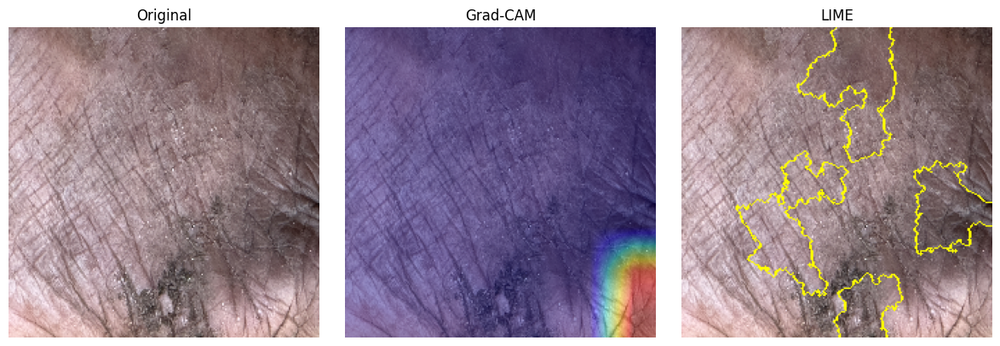

In [ ]:
"""
DAY 4: Grad-CAM + LIME explanations for the trained model.
Produces heatmaps you can save/show in the demo and poster.

pip install lime --break-system-packages   # if not already installed
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.efficientnet import preprocess_input
from lime import lime_image
from skimage.segmentation import mark_boundaries

MODEL_PATH = "arsenicnet_baseline.keras"
IMG_SIZE = (224, 224)

model = tf.keras.models.load_model(MODEL_PATH)

# EfficientNetB0's last conv block name — adjust if you change the backbone
LAST_CONV_LAYER = "top_conv"


# IMPORTANT: must match the preprocessing used during training
# (01b_train_final_model.py used efficientnet.preprocess_input, NOT /255.0).
# `raw` = original 0-255 image, only for DISPLAY.
# `model_input` = properly preprocessed version, for the model/Grad-CAM/LIME.
def load_img_array(img_path):
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    raw = keras_image.img_to_array(img)              # 0-255, for display
    model_input = preprocess_input(raw.copy())        # for model.predict / Grad-CAM
    display_arr = raw / 255.0                          # for matplotlib imshow
    return display_arr, model_input


# ---------------- Grad-CAM ----------------
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(np.expand_dims(img_array, axis=0))
        class_channel = predictions[:, 0]  # binary sigmoid output

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(predictions[0][0])


def overlay_gradcam(display_arr, heatmap, alpha=0.4):
    # display_arr must be the 0-1 scaled array (for correct imshow blending),
    # NOT the preprocess_input version.
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], IMG_SIZE
    ).numpy().squeeze()
    jet = cm.get_cmap("jet")
    jet_heatmap = jet(heatmap_resized)[:, :, :3]
    overlay = jet_heatmap * alpha + display_arr * (1 - alpha)
    return overlay


# ---------------- LIME ----------------
def predict_fn(images_batch):
    # LIME feeds raw 0-255 uint8 perturbed images -- apply the SAME
    # preprocessing the model was trained with before predicting.
    images_batch = preprocess_input(images_batch.astype("float32"))
    preds = model.predict(images_batch, verbose=0)
    return np.hstack([1 - preds, preds])  # [P(healthy), P(arsenic)] for LIME


def run_lime(raw_uint8_img):
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        raw_uint8_img,
        predict_fn,
        top_labels=2,
        hide_color=0,
        num_samples=500,   # lower for speed; raise to 1000+ if time allows
    )
    temp, mask = explanation.get_image_and_mask(
        explanation.top_labels[0], positive_only=True, num_features=6, hide_rest=False
    )
    return mark_boundaries(temp / 255.0, mask), mask


# ---------------- Run on one example ----------------
if __name__ == "__main__":
    img_path = "/content/data/original/affected/IMG_2043.JPG"  # change to a real test image
    display_arr, model_input = load_img_array(img_path)

    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    gradcam_overlay = overlay_gradcam(display_arr, heatmap)
    lime_overlay, lime_mask = run_lime((display_arr * 255).astype("uint8"))

    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"
    print(f"Prediction: {label} (confidence {pred_prob:.3f})")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
    axes[2].imshow(lime_overlay); axes[2].set_title("LIME"); axes[2].axis("off")
    plt.tight_layout()
    plt.savefig("explanation_example.png", dpi=150)
    plt.show()

    # heatmap and lime_mask are reused in 03_ontology_rules.py and
    # 04_faithfulness_check.py — save them so later scripts don't retrain
    np.save("gradcam_heatmap.npy", heatmap)
    np.save("lime_mask.npy", lime_mask)

In [ ]:
import os
print(os.listdir("/content/data/original/healthy")[:5])

['IMG_1631.JPG', 'IMG_1817.JPG', 'IMG_1874.JPG', 'IMG_1478.JPG', 'IMG_1348.JPG']


In [ ]:
IMAGES_TO_TEST = [
    ("/content/data/original/affected/IMG_2043.JPG", "affected_1_misclassified"),
    ("/content/data/original/affected/IMG20230610175248.jpg", "affected_2"),
    ("/content/data/original/healthy/IMG_1631.JPG", "healthy_1"),
    ("/content/data/original/healthy/IMG_1817.JPG", "healthy_2"),
]

In [ ]:
import os
affected_dir = "/content/data/original/affected"
sample_files = os.listdir(affected_dir)[:10]  # প্রথম ১০টা চেক করো

for fname in sample_files:
    path = os.path.join(affected_dir, fname)
    _, model_input = load_img_array(path)
    import numpy as np
    pred = model.predict(np.expand_dims(model_input, axis=0), verbose=0)[0][0]
    label = "Arsenic-affected" if pred > 0.5 else "Healthy"
    print(f"{fname}: {label} (confidence {pred:.3f})")

IMG_2043.JPG: Healthy (confidence 0.246)
IMG20230610180154.jpg: Arsenic-affected (confidence 0.959)
IMG20230610175248.jpg: Arsenic-affected (confidence 0.611)
IMG_1977.JPG: Arsenic-affected (confidence 0.770)
IMG_2040.JPG: Arsenic-affected (confidence 0.977)
IMG20230610180743.jpg: Arsenic-affected (confidence 0.974)
IMG20230610182515.jpg: Arsenic-affected (confidence 0.992)
IMG_20230616_153345.jpg: Arsenic-affected (confidence 0.971)
IMG-20230529-WA0008.jpg: Arsenic-affected (confidence 0.904)
IMG20230610181459.jpg: Arsenic-affected (confidence 0.527)


In [ ]:
IMAGES_TO_TEST = [
    ("/content/data/original/affected/IMG_2043.JPG", "affected_misclassified_conf0.25"),
    ("/content/data/original/affected/IMG20230610182515.jpg", "affected_correct_conf0.99"),
    ("/content/data/original/healthy/IMG_1631.JPG", "healthy_1"),
    ("/content/data/original/healthy/IMG_1817.JPG", "healthy_2"),
]


affected_misclassified_conf0.25: /content/data/original/affected/IMG_2043.JPG


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1219/2777907234.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


  0%|          | 0/500 [00:00<?, ?it/s]

Prediction: Healthy (confidence 0.246)


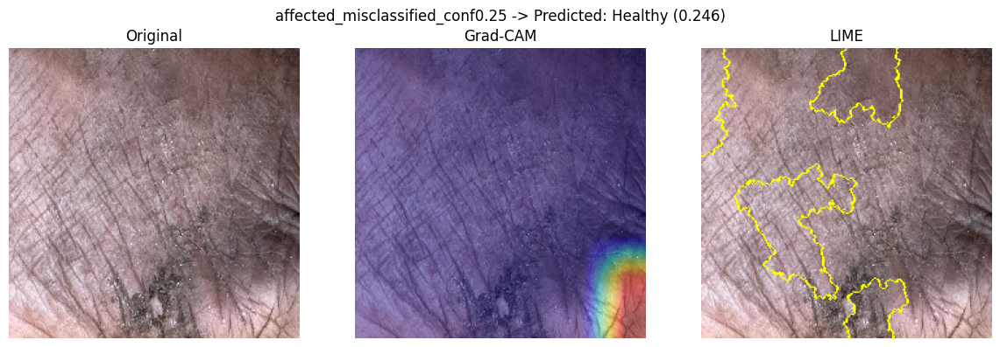


affected_correct_conf0.99: /content/data/original/affected/IMG20230610182515.jpg


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1219/2777907234.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


  0%|          | 0/500 [00:00<?, ?it/s]

Prediction: Arsenic-affected (confidence 0.992)


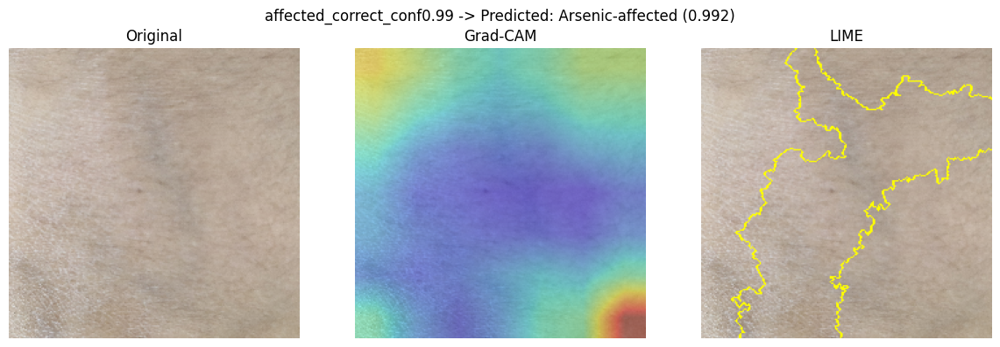


healthy_1: /content/data/original/healthy/IMG_1631.JPG


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1219/2777907234.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


  0%|          | 0/500 [00:00<?, ?it/s]

Prediction: Healthy (confidence 0.044)


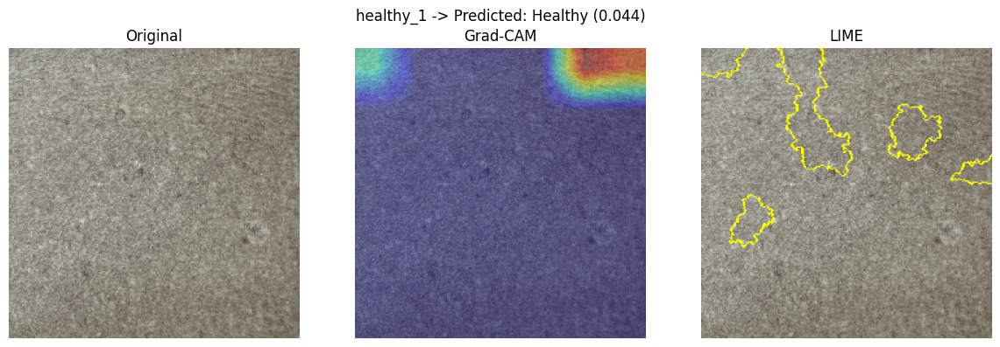


healthy_2: /content/data/original/healthy/IMG_1817.JPG


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1219/2777907234.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


  0%|          | 0/500 [00:00<?, ?it/s]

Prediction: Healthy (confidence 0.035)


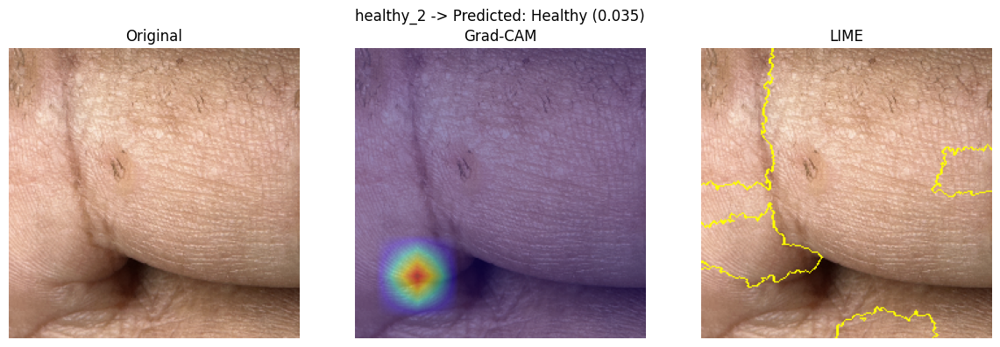

In [ ]:
"""
Batch Grad-CAM + LIME run — run AFTER the function-definition cells
from 02_explainability.py have already been executed (model load,
load_img_array, make_gradcam_heatmap, overlay_gradcam, run_lime, LAST_CONV_LAYER).
"""

IMAGES_TO_TEST = [
    ("/content/data/original/affected/IMG_2043.JPG", "affected_misclassified_conf0.25"),
    ("/content/data/original/affected/IMG20230610182515.jpg", "affected_correct_conf0.99"),
    ("/content/data/original/healthy/IMG_1631.JPG", "healthy_1"),
    ("/content/data/original/healthy/IMG_1817.JPG", "healthy_2"),
]

for img_path, tag in IMAGES_TO_TEST:
    print(f"\n{'='*50}\n{tag}: {img_path}\n{'='*50}")

    display_arr, model_input = load_img_array(img_path)
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    gradcam_overlay = overlay_gradcam(display_arr, heatmap)
    lime_overlay, lime_mask = run_lime((display_arr * 255).astype("uint8"))

    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"
    print(f"Prediction: {label} (confidence {pred_prob:.3f})")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(f"{tag} -> Predicted: {label} ({pred_prob:.3f})")
    axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
    axes[2].imshow(lime_overlay); axes[2].set_title("LIME"); axes[2].axis("off")
    plt.tight_layout()
    plt.savefig(f"explanation_{tag}.png", dpi=150)
    plt.show()

In [ ]:
from google.colab import files
files.download("explanation_affected_correct_conf0.99.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

for tag in ["affected_misclassified_conf0.25", "affected_correct_conf0.99", "healthy_1", "healthy_2"]:
    files.download(f"explanation_{tag}.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
os.makedirs("/content/drive/MyDrive/arsenicosis_data/checkpoints", exist_ok=True)

!cp arsenicnet_baseline.keras /content/drive/MyDrive/arsenicosis_data/checkpoints/
!cp explanation_*.png /content/drive/MyDrive/arsenicosis_data/checkpoints/
!cp arsenicosis_ontology.ttl /content/drive/MyDrive/arsenicosis_data/checkpoints/ 2>/dev/null

print("Backed up to Drive:")
!ls /content/drive/MyDrive/arsenicosis_data/checkpoints/

Backed up to Drive:
 arsenicnet_baseline.keras
'explanation_affected_1_(misclassified_earlier).png'
 explanation_affected_correct_conf0.99.png
 explanation_affected_misclassified_conf0.25.png
 explanation_example.png
 explanation_healthy_1.png
 explanation_healthy_2.png


In [ ]:
"""
DAY 6 (the new small contribution): Quantify whether Grad-CAM/LIME
explanations actually point at the lesion, instead of just eyeballing
sample images. This is what makes your poster stand out with real rigor.

Approach for 8/9-day timeline (no time to get a clinician to draw exact
lesion masks for hundreds of images):
1. Take ~15-20 test images.
2. Draw a rough bounding box around the visible lesion yourself using
   the helper below (one click-drag per image) -- this acts as a cheap
   "pseudo ground-truth" region.
3. Compute overlap between that box and the Grad-CAM heatmap's high-
   activation region (IoU-style score).
4. Report the average faithfulness score on the poster as a first-pass
   quantitative check, and note it as a pilot for future clinician-
   validated evaluation.
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import RectangleSelector

# ---------------- Step 1: quick manual box annotation tool ----------------
_boxes = {}


def annotate_box(img_array, img_id):
    """
    Opens a window; drag a rectangle around the lesion, then close the
    window. Box is stored in _boxes[img_id] as (x1, y1, x2, y2).
    Run this once per sample image (repeat for ~15-20 images).
    """
    fig, ax = plt.subplots()
    ax.imshow(img_array)
    ax.set_title(f"Drag a box around the lesion: {img_id}")

    def onselect(eclick, erelease):
        x1, y1 = int(eclick.xdata), int(eclick.ydata)
        x2, y2 = int(erelease.xdata), int(erelease.ydata)
        _boxes[img_id] = (min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2))
        print(f"Saved box for {img_id}: {_boxes[img_id]}")

    selector = RectangleSelector(ax, onselect, useblit=True, button=[1])
    plt.show()
    return _boxes.get(img_id)


# ---------------- Step 2: overlap score between box and heatmap ----------------
def heatmap_to_binary_mask(heatmap, img_size, threshold=0.5):
    """Resize heatmap to image size and threshold to a binary 'attention region'."""
    import tensorflow as tf
    resized = tf.image.resize(heatmap[..., np.newaxis], img_size).numpy().squeeze()
    return (resized >= threshold).astype(np.uint8)


def box_to_mask(box, img_size):
    mask = np.zeros(img_size, dtype=np.uint8)
    x1, y1, x2, y2 = box
    mask[y1:y2, x1:x2] = 1
    return mask


def iou_score(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum()
    union = np.logical_or(mask_a, mask_b).sum()
    return intersection / union if union > 0 else 0.0


def faithfulness_score(gradcam_heatmap, lesion_box, img_size=(224, 224), threshold=0.5):
    """
    Returns an IoU-style faithfulness score in [0, 1]:
    higher = Grad-CAM's high-activation region overlaps more with the
    (roughly annotated) lesion location.
    """
    heat_mask = heatmap_to_binary_mask(gradcam_heatmap, img_size, threshold)
    box_mask = box_to_mask(lesion_box, img_size)
    return iou_score(heat_mask, box_mask)


# ---------------- Step 3: run across your ~15-20 annotated samples ----------------
def summarize_faithfulness(scores: list[float]):
    scores = np.array(scores)
    print(f"n = {len(scores)}")
    print(f"Mean faithfulness (IoU): {scores.mean():.3f}")
    print(f"Median: {np.median(scores):.3f}  |  Min: {scores.min():.3f}  |  Max: {scores.max():.3f}")
    return {
        "mean": float(scores.mean()),
        "median": float(np.median(scores)),
        "n": len(scores),
    }


if __name__ == "__main__":
    # Example usage once you have heatmaps (from 02_explainability.py)
    # and boxes (from annotate_box) for each sample:
    #
    # heatmap = np.load("gradcam_heatmap.npy")
    # box = _boxes["sample_001"]
    # score = faithfulness_score(heatmap, box)
    #
    # Collect scores for all annotated samples into a list, then:
    # summarize_faithfulness(all_scores)
    print("See comments for usage — run interactively in Jupyter/Colab.")


See comments for usage — run interactively in Jupyter/Colab.


In [ ]:
"""
DAY 6: Explanation faithfulness check -- Colab-friendly version.

Avoids interactive matplotlib widgets entirely (they're unreliable in
Colab). Instead: show the image with a pixel-coordinate grid, you look
at it and type in the box coordinates as plain numbers. Works with
Colab's default inline backend, no %matplotlib widget / ipympl needed.
"""

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

IMG_SIZE = (224, 224)


# ---------------- Step 1: show image with a coordinate grid ----------------
def show_with_grid(display_arr, title=""):
    """
    Displays the image with axis ticks every 20px so you can read off
    approximate (x1, y1, x2, y2) for the lesion by eye.
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(display_arr)
    ax.set_xticks(np.arange(0, IMG_SIZE[0] + 1, 20))
    ax.set_yticks(np.arange(0, IMG_SIZE[1] + 1, 20))
    ax.grid(color="cyan", linewidth=0.5, alpha=0.6)
    ax.set_title(title)
    plt.show()


# ---------------- Step 2: you type in the box after looking at the grid -----
# Example workflow (run these three lines per image):
#   display_arr, model_input = load_img_array(img_path)
#   show_with_grid(display_arr, "IMG20230610182515.jpg")
#   boxes["IMG20230610182515"] = (55, 40, 160, 150)   # x1, y1, x2, y2 -- read off the grid

boxes = {}   # img_id -> (x1, y1, x2, y2), fill this in as you go


# ---------------- Step 3: overlap score between box and heatmap ----------------
def heatmap_to_binary_mask(heatmap, img_size=IMG_SIZE, threshold=0.5):
    resized = tf.image.resize(heatmap[..., np.newaxis], img_size).numpy().squeeze()
    return (resized >= threshold).astype(np.uint8)


def box_to_mask(box, img_size=IMG_SIZE):
    mask = np.zeros(img_size, dtype=np.uint8)
    x1, y1, x2, y2 = box
    mask[y1:y2, x1:x2] = 1
    return mask


def iou_score(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum()
    union = np.logical_or(mask_a, mask_b).sum()
    return intersection / union if union > 0 else 0.0


def faithfulness_score(gradcam_heatmap, lesion_box, img_size=IMG_SIZE, threshold=0.5):
    heat_mask = heatmap_to_binary_mask(gradcam_heatmap, img_size, threshold)
    box_mask = box_to_mask(lesion_box, img_size)
    return iou_score(heat_mask, box_mask)


def summarize_faithfulness(scores_dict):
    """scores_dict: {img_id: score}"""
    scores = np.array(list(scores_dict.values()))
    print(f"{'Image':<45}{'Score':>8}")
    for img_id, score in scores_dict.items():
        print(f"{img_id:<45}{score:>8.3f}")
    print(f"\nn = {len(scores)}")
    print(f"Mean faithfulness (IoU): {scores.mean():.3f}")
    print(f"Median: {np.median(scores):.3f} | Min: {scores.min():.3f} | Max: {scores.max():.3f}")
    return {"mean": float(scores.mean()), "median": float(np.median(scores)), "n": len(scores)}


# ---------------- Full workflow example ----------------
"""
Run this pattern for each of your ~15-20 sample images (copy/adapt into
Colab cells one image at a time):

    img_path = "/content/data/original/affected/IMG20230610182515.jpg"
    img_id = "IMG20230610182515"

    display_arr, model_input = load_img_array(img_path)          # from 02_explainability.py
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)

    show_with_grid(display_arr, img_id)
    # -- look at the printed grid, find where the lesion/discoloration is,
    #    read off approximate pixel coordinates --

    boxes[img_id] = (x1, y1, x2, y2)   # type the 4 numbers you read off

    score = faithfulness_score(heatmap, boxes[img_id])
    print(f"{img_id}: faithfulness = {score:.3f}")

After doing this for all sample images, collect results into a dict and
summarize:

    all_scores = {}
    for img_id, box in boxes.items():
        # you'd need to keep each image's heatmap around, or recompute it here
        all_scores[img_id] = faithfulness_score(heatmap_for[img_id], box)

    summarize_faithfulness(all_scores)
"""

'\nRun this pattern for each of your ~15-20 sample images (copy/adapt into\nColab cells one image at a time):\n\n    img_path = "/content/data/original/affected/IMG20230610182515.jpg"\n    img_id = "IMG20230610182515"\n\n    display_arr, model_input = load_img_array(img_path)          # from 02_explainability.py\n    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)\n\n    show_with_grid(display_arr, img_id)\n    # -- look at the printed grid, find where the lesion/discoloration is,\n    #    read off approximate pixel coordinates --\n\n    boxes[img_id] = (x1, y1, x2, y2)   # type the 4 numbers you read off\n\n    score = faithfulness_score(heatmap, boxes[img_id])\n    print(f"{img_id}: faithfulness = {score:.3f}")\n\nAfter doing this for all sample images, collect results into a dict and\nsummarize:\n\n    all_scores = {}\n    for img_id, box in boxes.items():\n        # you\'d need to keep each image\'s heatmap around, or recompute it here\n        all_s

In [ ]:
"""
DAY 6 (batch, recommended): Loops through all your sample images, shows
each with a coordinate grid, and asks you to type the box coordinates
via input() -- works in any Colab cell, no widgets needed.

Run AFTER the function-definition cells from 02_explainability.py are
already executed (model, load_img_array, make_gradcam_heatmap, LAST_CONV_LAYER)
and after running 04_faithfulness_check.py's function definitions
(show_with_grid, faithfulness_score, summarize_faithfulness).
"""

# ---- Edit this list: your ~15-20 sample images (mostly 'affected', since
# healthy images have no lesion to box) ----
SAMPLE_IMAGES = [
    ("/content/data/original/affected/IMG20230610182515.jpg", "IMG20230610182515"),
    ("/content/data/original/affected/IMG_2043.JPG", "IMG_2043"),
    ("/content/data/original/affected/IMG20230610180154.jpg", "IMG20230610180154"),
    ("/content/data/original/affected/IMG_1977.JPG", "IMG_1977"),
    ("/content/data/original/affected/IMG_2040.JPG", "IMG_2040"),
    ("/content/data/original/affected/IMG20230610180743.jpg", "IMG20230610180743"),
    ("/content/data/original/affected/IMG_20230616_153345.jpg", "IMG_20230616_153345"),
    ("/content/data/original/affected/IMG-20230529-WA0008.jpg", "IMG-20230529-WA0008"),
    ("/content/data/original/affected/IMG20230610181459.jpg", "IMG20230610181459"),
    # add more up to ~15-20 total
]

all_scores = {}
all_predictions = {}

for img_path, img_id in SAMPLE_IMAGES:
    print(f"\n{'='*60}\n{img_id}\n{'='*60}")

    display_arr, model_input = load_img_array(img_path)
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"
    all_predictions[img_id] = (label, pred_prob)
    print(f"Prediction: {label} (confidence {pred_prob:.3f})")

    show_with_grid(display_arr, img_id)

    # -- type the lesion box coordinates you read off the grid --
    print("Look at the grid above. Enter the box around the visible lesion/")
    print("discoloration (approximate is fine). Type 4 numbers separated by spaces.")
    print("Format: x1 y1 x2 y2   (top-left corner, then bottom-right corner)")
    print("If no lesion is clearly visible, type: 0 0 0 0  (will score as 0)")

    coords = input(f"Box for {img_id}: ").strip()
    x1, y1, x2, y2 = map(int, coords.split())

    if (x1, y1, x2, y2) == (0, 0, 0, 0):
        score = 0.0
    else:
        score = faithfulness_score(heatmap, (x1, y1, x2, y2))

    all_scores[img_id] = score
    print(f"Faithfulness score for {img_id}: {score:.3f}")

# ---- Final summary across all images ----
print(f"\n{'='*60}\nFINAL FAITHFULNESS SUMMARY\n{'='*60}")
summarize_faithfulness(all_scores)

print("\nPredictions recap:")
for img_id, (label, conf) in all_predictions.items():
    print(f"  {img_id}: {label} ({conf:.3f}) -> faithfulness {all_scores[img_id]:.3f}")


IMG20230610182515


NameError: name 'load_img_array' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/drive/MyDrive/arsenicosis_data/checkpoints/arsenicnet_baseline.keras /content/

import tensorflow as tf
model = tf.keras.models.load_model("arsenicnet_baseline.keras")
print("Model loaded, no retraining needed!")

Mounted at /content/drive
Model loaded, no retraining needed!


In [ ]:
!unzip -q "/content/drive/MyDrive/Original.zip" -d "/content/data"

In [ ]:
!ls /content/data/Original

infacted  not_infacted


In [ ]:
import os
print(os.listdir("/content/data/Original/infacted")[:5])

['IMG_1782.JPG', 'IMG_1283.JPG', 'IMG_1849.JPG', 'IMG_1875.JPG', 'IMG_1596.JPG']


In [ ]:
!pip install lime scikit-image --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.efficientnet import preprocess_input
from lime import lime_image
from skimage.segmentation import mark_boundaries

# ---------------- Config ----------------
MODEL_PATH = "arsenicnet_baseline.keras"
IMG_SIZE = (224, 224)
LAST_CONV_LAYER = "top_conv"  # EfficientNetB0's last conv block

# ---------------- Load model (must already be copied to /content/) ----------------
model = tf.keras.models.load_model(MODEL_PATH)
print(f"Model loaded from {MODEL_PATH}")


def load_img_array(img_path):
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    raw = keras_image.img_to_array(img)
    model_input = preprocess_input(raw.copy())
    display_arr = raw / 255.0
    return display_arr, model_input


def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(np.expand_dims(img_array, axis=0))
        class_channel = predictions[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(predictions[0][0])


def overlay_gradcam(display_arr, heatmap, alpha=0.4):
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], IMG_SIZE
    ).numpy().squeeze()
    jet = plt.get_cmap("jet")
    jet_heatmap = jet(heatmap_resized)[:, :, :3]
    overlay = jet_heatmap * alpha + display_arr * (1 - alpha)
    return overlay


def predict_fn(images_batch):
    images_batch = preprocess_input(images_batch.astype("float32"))
    preds = model.predict(images_batch, verbose=0)
    return np.hstack([1 - preds, preds])


def run_lime(raw_uint8_img):
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        raw_uint8_img, predict_fn, top_labels=2, hide_color=0, num_samples=500,
    )
    temp, mask = explanation.get_image_and_mask(
        explanation.top_labels[0], positive_only=True, num_features=6, hide_rest=False
    )
    return mark_boundaries(temp / 255.0, mask), mask


def show_with_grid(display_arr, title=""):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(display_arr)
    ax.set_xticks(np.arange(0, IMG_SIZE[0] + 1, 20))
    ax.set_yticks(np.arange(0, IMG_SIZE[1] + 1, 20))
    ax.grid(color="cyan", linewidth=0.5, alpha=0.6)
    ax.set_title(title)
    plt.show()


def heatmap_to_binary_mask(heatmap, img_size=IMG_SIZE, threshold=0.5):
    resized = tf.image.resize(heatmap[..., np.newaxis], img_size).numpy().squeeze()
    return (resized >= threshold).astype(np.uint8)


def box_to_mask(box, img_size=IMG_SIZE):
    mask = np.zeros(img_size, dtype=np.uint8)
    x1, y1, x2, y2 = box
    mask[y1:y2, x1:x2] = 1
    return mask


def iou_score(mask_a, mask_b):
    intersection = np.logical_and(mask_a, mask_b).sum()
    union = np.logical_or(mask_a, mask_b).sum()
    return intersection / union if union > 0 else 0.0


def faithfulness_score(gradcam_heatmap, lesion_box, img_size=IMG_SIZE, threshold=0.5):
    heat_mask = heatmap_to_binary_mask(gradcam_heatmap, img_size, threshold)
    box_mask = box_to_mask(lesion_box, img_size)
    return iou_score(heat_mask, box_mask)


def summarize_faithfulness(scores_dict):
    scores = np.array(list(scores_dict.values()))
    print(f"{'Image':<45}{'Score':>8}")
    for img_id, score in scores_dict.items():
        print(f"{img_id:<45}{score:>8.3f}")
    print(f"\nn = {len(scores)}")
    print(f"Mean faithfulness (IoU): {scores.mean():.3f}")
    print(f"Median: {np.median(scores):.3f} | Min: {scores.min():.3f} | Max: {scores.max():.3f}")
    return {"mean": float(scores.mean()), "median": float(np.median(scores)), "n": len(scores)}


print("Setup complete -- load_img_array, make_gradcam_heatmap, overlay_gradcam, "
      "run_lime, show_with_grid, faithfulness_score, summarize_faithfulness all ready.")

Model loaded from arsenicnet_baseline.keras
Setup complete -- load_img_array, make_gradcam_heatmap, overlay_gradcam, run_lime, show_with_grid, faithfulness_score, summarize_faithfulness all ready.


18 images:
  IMG_1169
  IMG_1170
  IMG_1171
  IMG_1172
  IMG_1173
  IMG_1174
  IMG_1175
  IMG_1176
  IMG_1177
  IMG_1178
  IMG_1179
  IMG_1180
  IMG_1181
  IMG_1182
  IMG_1183
  IMG_1184
  IMG_1185
  IMG_1186


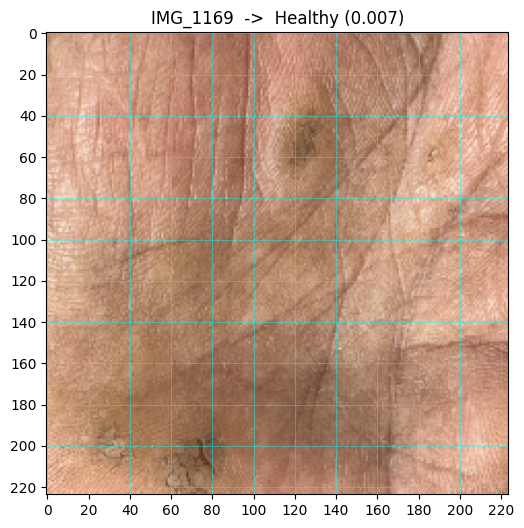

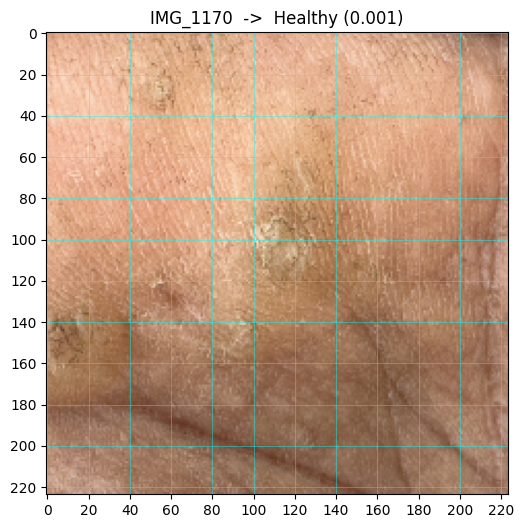

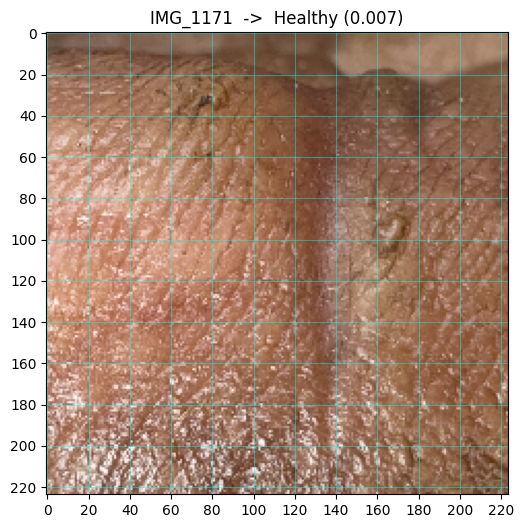

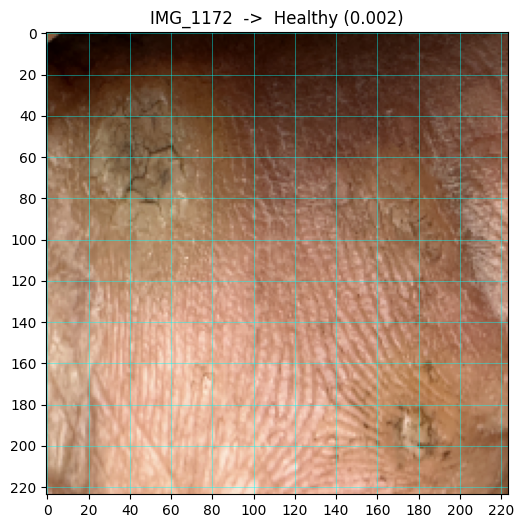

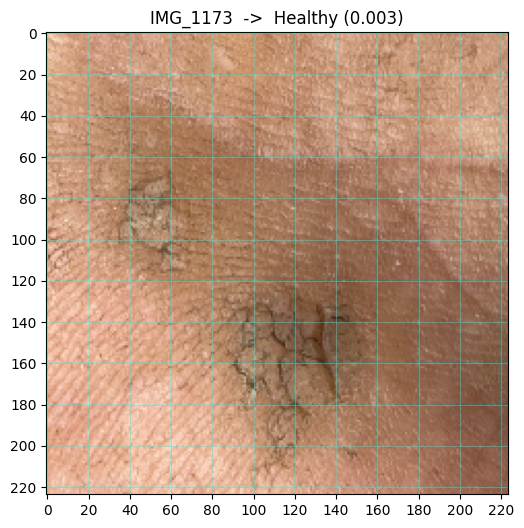

...

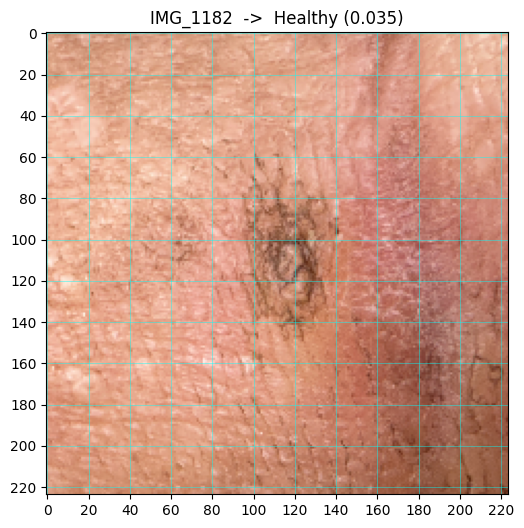

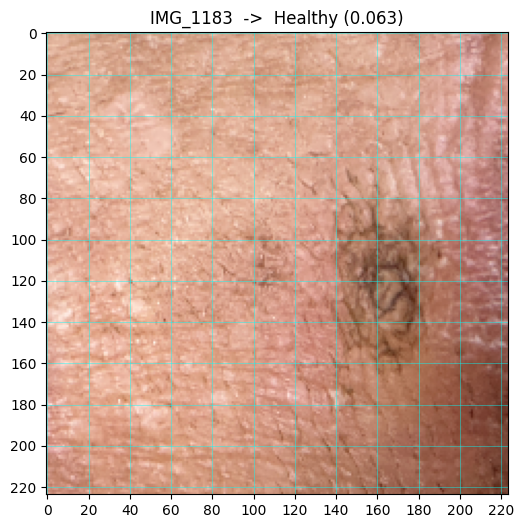

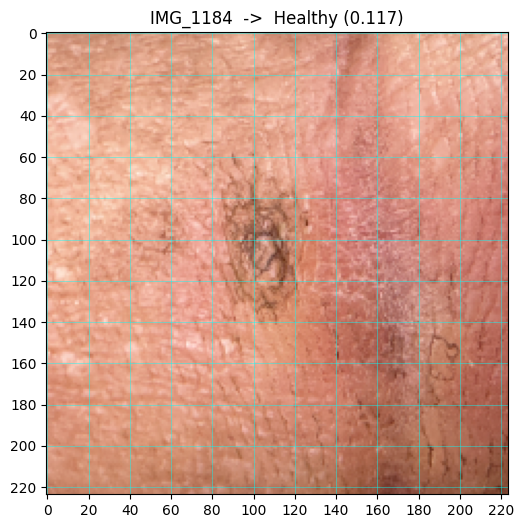

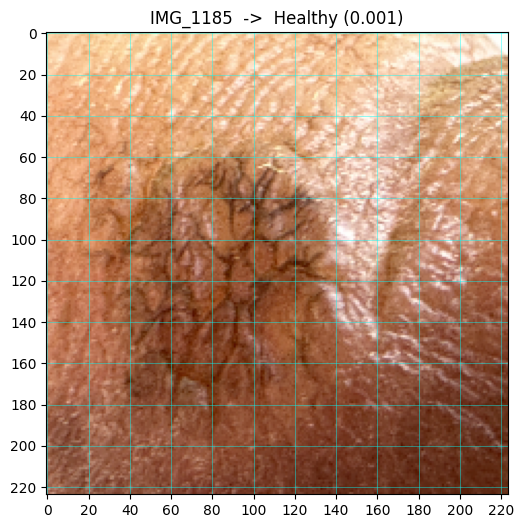

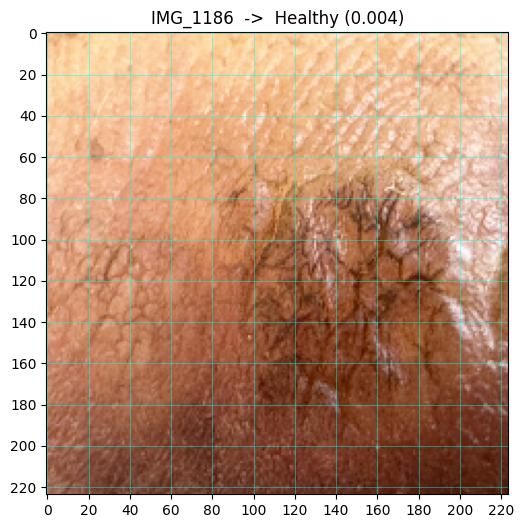


All images displayed. Now fill in LESION_BOXES in 04c_faithfulness_scoring.py based on what you see above, then run it.


In [ ]:
"""
DAY 6 -- STEP A: Just display all sample images with the coordinate grid,
no input() needed. Take a screenshot of each (or view them here in Colab),
then fill in LESION_BOXES in 04c_faithfulness_scoring.py based on what you see.

Run AFTER 00_session_setup.py has been executed in this session.
"""

import os

infacted_dir = "/content/data/Original/infacted"
sample_files = sorted(os.listdir(infacted_dir))[:18]

SAMPLE_IMAGES = [
    (os.path.join(infacted_dir, fname), fname.split(".")[0])
    for fname in sample_files
]

print(f"{len(SAMPLE_IMAGES)} images:")
for _, img_id in SAMPLE_IMAGES:
    print(f"  {img_id}")

# ---- Show every image with grid + prediction, store heatmaps for later ----
heatmaps = {}       # img_id -> heatmap (needed in step B)
predictions = {}    # img_id -> (label, confidence)

for img_path, img_id in SAMPLE_IMAGES:
    display_arr, model_input = load_img_array(img_path)
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

    heatmaps[img_id] = heatmap
    predictions[img_id] = (label, pred_prob)

    show_with_grid(display_arr, f"{img_id}  ->  {label} ({pred_prob:.3f})")

print("\nAll images displayed. Now fill in LESION_BOXES in "
      "04c_faithfulness_scoring.py based on what you see above, then run it.")

In [ ]:
"""
DAY 6 -- STEP B: Fill in the box coordinates you read off each grid from
04b_show_all_grids.py, then run this cell to compute + summarize
faithfulness scores. No input() prompts -- edit the dictionary, run once.

Must run AFTER 04b_show_all_grids.py in the same session (needs `heatmaps`
and `predictions` dicts it created).
"""

# ---- Fill in (x1, y1, x2, y2) for each image based on the grids you saw ----
# Leave an image out of this dict (or comment it out) if no lesion was
# visible -- it will simply be skipped / scored as 0 depending on setting.
LESION_BOXES = {
    "IMG_1169": (95, 25, 145, 70),   # example from the screenshot you showed
    # "IMG_1170": (x1, y1, x2, y2),
    # "IMG_1171": (x1, y1, x2, y2),
    # "IMG_1172": (x1, y1, x2, y2),
    # ... add the rest here as you review each grid image
}

SCORE_MISSING_AS_ZERO = True  # if True, images not in LESION_BOXES count as score 0
                               # if False, they're skipped entirely from the average

all_scores = {}

for img_id, heatmap in heatmaps.items():
    label, conf = predictions[img_id]

    if img_id in LESION_BOXES:
        box = LESION_BOXES[img_id]
        score = faithfulness_score(heatmap, box)
    elif SCORE_MISSING_AS_ZERO:
        score = 0.0
    else:
        continue  # skip entirely

    all_scores[img_id] = score
    print(f"{img_id:<15} pred={label:<17} conf={conf:.3f}  faithfulness={score:.3f}")

print(f"\n{'='*60}\nFINAL FAITHFULNESS SUMMARY\n{'='*60}")
summarize_faithfulness(all_scores)

IMG_1169        pred=Healthy           conf=0.007  faithfulness=0.000
IMG_1170        pred=Healthy           conf=0.001  faithfulness=0.000
IMG_1171        pred=Healthy           conf=0.007  faithfulness=0.000
IMG_1172        pred=Healthy           conf=0.002  faithfulness=0.000
IMG_1173        pred=Healthy           conf=0.003  faithfulness=0.000
IMG_1174        pred=Healthy           conf=0.007  faithfulness=0.000
IMG_1175        pred=Healthy           conf=0.001  faithfulness=0.000
IMG_1176        pred=Healthy           conf=0.002  faithfulness=0.000
IMG_1177        pred=Healthy           conf=0.060  faithfulness=0.000
IMG_1178        pred=Healthy           conf=0.013  faithfulness=0.000
IMG_1179        pred=Healthy           conf=0.007  faithfulness=0.000
IMG_1180        pred=Healthy           conf=0.003  faithfulness=0.000
IMG_1181        pred=Healthy           conf=0.009  faithfulness=0.000
IMG_1182        pred=Healthy           conf=0.035  faithfulness=0.000
IMG_1183        pred

{'mean': 0.0, 'median': 0.0, 'n': 18}

In [ ]:
import os
import numpy as np

# 'not_infacted' (healthy) ফোল্ডার থেকে কয়েকটা ছবি টেস্ট করো
not_infacted_dir = "/content/data/Original/not_infacted"
sample = sorted(os.listdir(not_infacted_dir))[:5]

for fname in sample:
    path = os.path.join(not_infacted_dir, fname)
    _, model_input = load_img_array(path)
    pred = model.predict(np.expand_dims(model_input, axis=0), verbose=0)[0][0]
    label = "Arsenic-affected" if pred > 0.5 else "Healthy"
    print(f"{fname} (true=not_infacted/healthy): {label} ({pred:.3f})")

IMG-20230529-WA0000.jpg (true=not_infacted/healthy): Arsenic-affected (0.734)
IMG-20230529-WA0001.jpg (true=not_infacted/healthy): Arsenic-affected (0.933)
IMG-20230529-WA0002.jpg (true=not_infacted/healthy): Arsenic-affected (0.938)
IMG-20230529-WA0003.jpg (true=not_infacted/healthy): Arsenic-affected (0.935)
IMG-20230529-WA0004.jpg (true=not_infacted/healthy): Arsenic-affected (0.530)


In [ ]:
"""
FINAL MODEL TRAINING (for Grad-CAM / LIME / demo app use).

Not a cross-validation run -- this trains ONE final model on a normal
train/val split of the ORIGINAL images and SAVES it, since 01_train_model_kfold.py
intentionally does not keep any model (it only reports CV metrics).

Run this AFTER confirming the full 1,482-image dataset (741 healthy +
741 affected) is correctly present -- see note below.
"""

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 12          # matches what already converged well in your CV run
DATA_DIR = "/content/data/Original"
MODEL_OUT = "arsenicnet_baseline.keras"
SEED = 42

# ---- Uses the dataset's ACTUAL folder names directly -- no manual
# copy/rename step, which is what caused the earlier label-swap bug. ----
CLASS_MAP = {"not_infacted": 0, "infacted": 1}  # 0=healthy, 1=affected

# ---- Build file list + labels ----
def build_filepaths_and_labels(data_dir):
    filepaths, labels = [], []
    for cls_name, cls_label in CLASS_MAP.items():
        cls_dir = os.path.join(data_dir, cls_name)
        for fname in os.listdir(cls_dir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                filepaths.append(os.path.join(cls_dir, fname))
                labels.append(cls_label)
    return np.array(filepaths), np.array(labels)

filepaths, labels = build_filepaths_and_labels(DATA_DIR)
print(f"Total images found: {len(filepaths)} "
      f"(healthy={sum(labels==0)}, affected={sum(labels==1)})")

# ---- 85/15 train/val split (single split, not CV) ----
train_fps, val_fps, train_lbls, val_lbls = train_test_split(
    filepaths, labels, test_size=0.15, stratify=labels, random_state=SEED
)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20, width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, zoom_range=0.15,
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

def make_generator(datagen, fps, lbls, shuffle):
    df = pd.DataFrame({"filename": fps, "class": lbls.astype(str)})
    return datagen.flow_from_dataframe(
        df, x_col="filename", y_col="class", target_size=IMG_SIZE,
        batch_size=BATCH_SIZE, class_mode="binary", shuffle=shuffle, seed=SEED,
    )

train_gen = make_generator(train_datagen, train_fps, train_lbls, shuffle=True)
val_gen = make_generator(val_datagen, val_fps, val_lbls, shuffle=False)
print("Class indices:", train_gen.class_indices)  # confirm 'affected' -> 1

# ---- Model (same architecture as the CV run) ----
base_model = EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(128, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
    ModelCheckpoint(MODEL_OUT, monitor="val_auc", mode="max", save_best_only=True),
]

model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS, callbacks=callbacks, verbose=2)

model.save(MODEL_OUT)
print(f"\nSaved final model to {MODEL_OUT} -- ready for 02_explainability.py")

Total images found: 1287 (healthy=546, affected=741)
Found 1093 validated image filenames belonging to 2 classes.
Found 194 validated image filenames belonging to 2 classes.
Class indices: {'0': 0, '1': 1}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
35/35 - 262s - 7s/step - accuracy: 0.6167 - auc: 0.6697 - loss: 0.7284 - val_accuracy: 0.7784 - val_auc: 0.8573 - val_loss: 0.5834 - learning_rate: 1.0000e-04
Epoch 2/12
35/35 - 214s - 6s/step - accuracy: 0.7731 - auc: 0.8575 - loss: 0.4806 - val_accuracy: 0.8711 - val_auc: 0.9438 - val_loss: 0.4868 - learning_rate: 1.0000e-04
Epoch 3/12
35/35 - 223s - 6s/step - accuracy: 0.8207 - auc: 0.9155 - loss: 0.3758 - val_accuracy: 0.8814 - val_auc: 0.9656 - val_loss: 0.4128 - learning_rate: 1.0000e-04
Epoch 4/12
35/35 - 217s - 6s/step - accuracy: 0.8527 - auc: 0.9328 - loss: 0.3324 - val_accuracy: 0.8557 - val_auc: 0.9749 - val_loss: 0.3693 - learning_rate: 1.0000e-04
Epoch 5/12
35/35 - 218s - 6s/step - accuracy: 0.8692 - auc: 0.9

In [ ]:
   !cp arsenicnet_baseline.keras /content/drive/MyDrive/arsenicosis_data/checkpoints/

In [ ]:
import os
import numpy as np

not_infacted_dir = "/content/data/Original/not_infacted"
infacted_dir = "/content/data/Original/infacted"

print("--- not_infacted (should predict Healthy) ---")
for fname in sorted(os.listdir(not_infacted_dir))[:5]:
    path = os.path.join(not_infacted_dir, fname)
    _, model_input = load_img_array(path)
    pred = model.predict(np.expand_dims(model_input, axis=0), verbose=0)[0][0]
    label = "Arsenic-affected" if pred > 0.5 else "Healthy"
    print(f"{fname}: {label} ({pred:.3f})")

print("\n--- infacted (should predict Arsenic-affected) ---")
for fname in sorted(os.listdir(infacted_dir))[:5]:
    path = os.path.join(infacted_dir, fname)
    _, model_input = load_img_array(path)
    pred = model.predict(np.expand_dims(model_input, axis=0), verbose=0)[0][0]
    label = "Arsenic-affected" if pred > 0.5 else "Healthy"
    print(f"{fname}: {label} ({pred:.3f})")

--- not_infacted (should predict Healthy) ---
IMG-20230529-WA0000.jpg: Healthy (0.189)
IMG-20230529-WA0001.jpg: Healthy (0.114)
IMG-20230529-WA0002.jpg: Healthy (0.027)
IMG-20230529-WA0003.jpg: Healthy (0.143)
IMG-20230529-WA0004.jpg: Healthy (0.356)

--- infacted (should predict Arsenic-affected) ---
IMG_1169.JPG: Arsenic-affected (0.975)
IMG_1170.JPG: Arsenic-affected (0.995)
IMG_1171.JPG: Arsenic-affected (0.936)
IMG_1172.JPG: Arsenic-affected (0.993)
IMG_1173.JPG: Arsenic-affected (0.991)


In [ ]:
!cp arsenicnet_baseline.keras /content/drive/MyDrive/arsenicosis_data/checkpoints/
print("Backed up corrected model to Drive")

Backed up corrected model to Drive


18 images:
  IMG_1169
  IMG_1170
  IMG_1171
  IMG_1172
  IMG_1173
  IMG_1174
  IMG_1175
  IMG_1176
  IMG_1177
  IMG_1178
  IMG_1179
  IMG_1180
  IMG_1181
  IMG_1182
  IMG_1183
  IMG_1184
  IMG_1185
  IMG_1186


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_1018']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


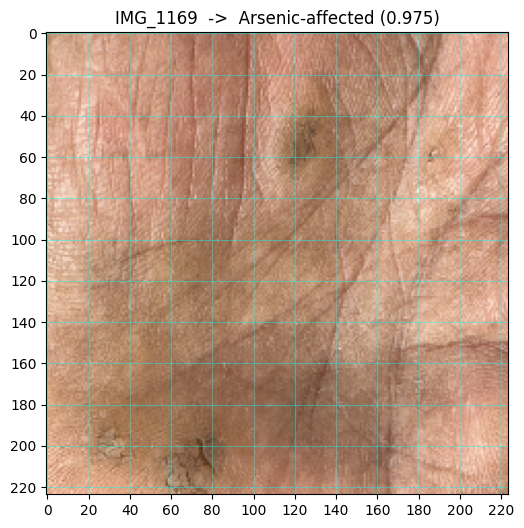

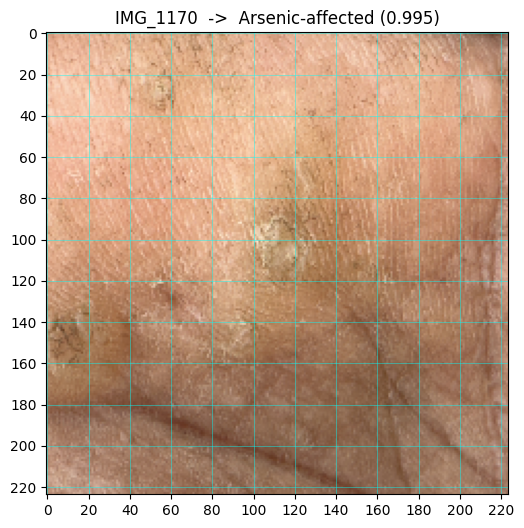

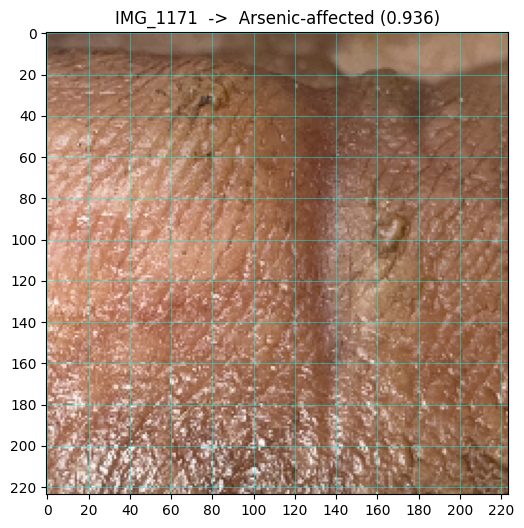

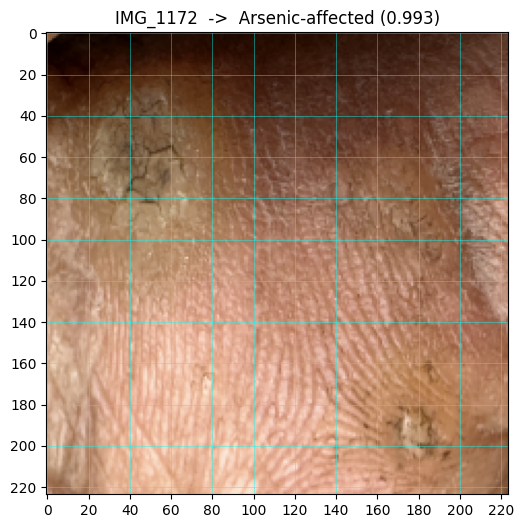

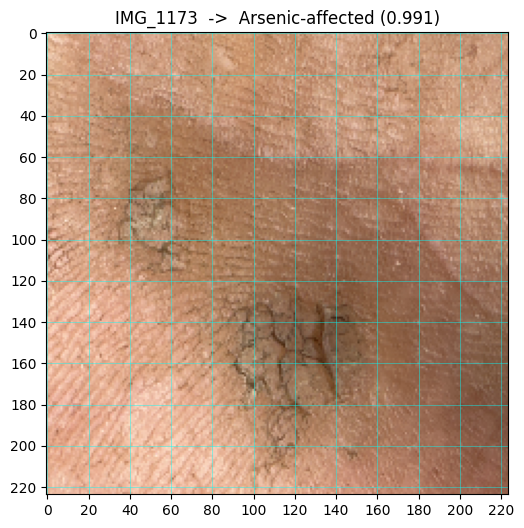

...

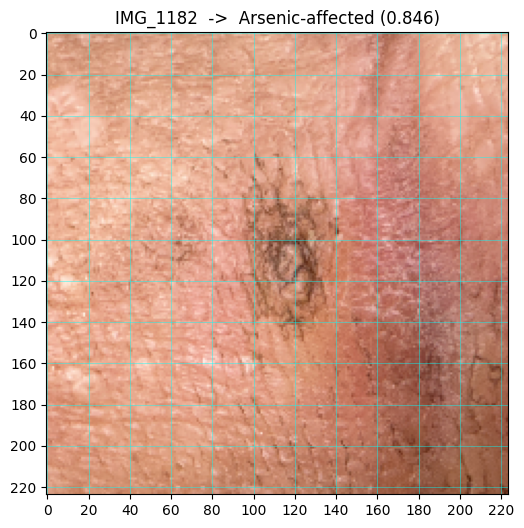

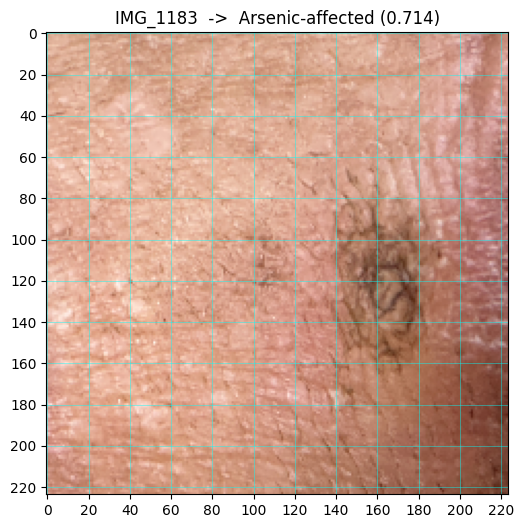

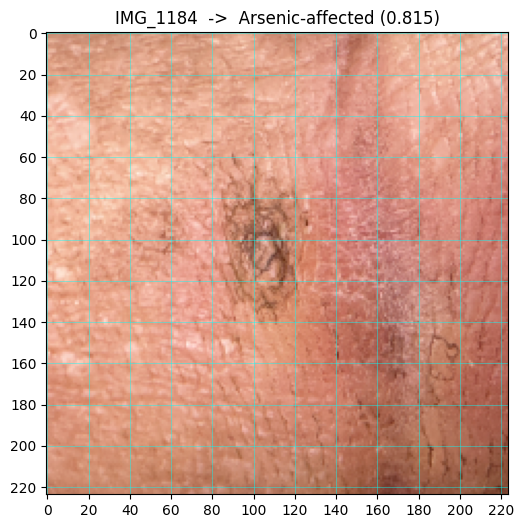

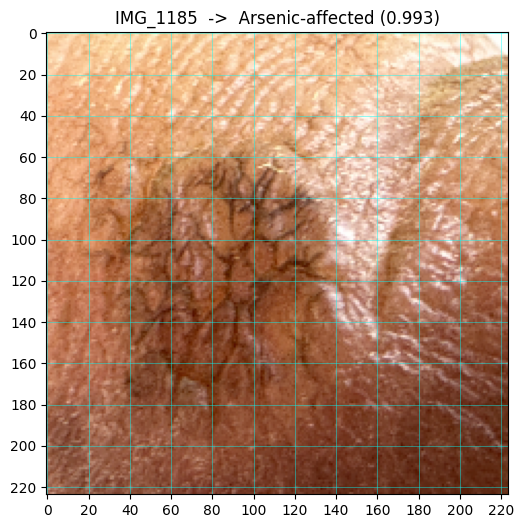

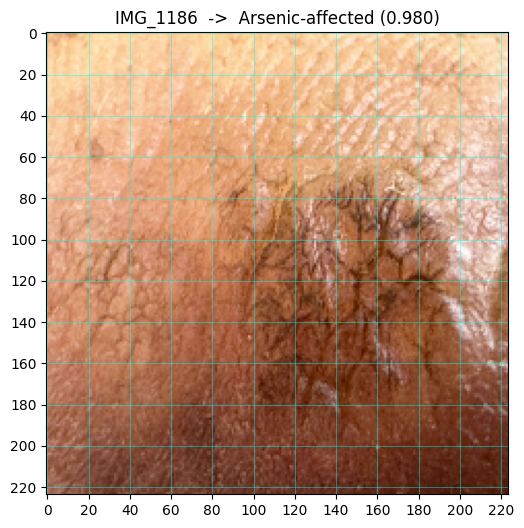


All images displayed. Now fill in LESION_BOXES in 04c_faithfulness_scoring.py based on what you see above, then run it.


In [ ]:
"""
DAY 6 -- STEP A: Just display all sample images with the coordinate grid,
no input() needed. Take a screenshot of each (or view them here in Colab),
then fill in LESION_BOXES in 04c_faithfulness_scoring.py based on what you see.

Run AFTER 00_session_setup.py has been executed in this session.
"""

import os

infacted_dir = "/content/data/Original/infacted"
sample_files = sorted(os.listdir(infacted_dir))[:18]

SAMPLE_IMAGES = [
    (os.path.join(infacted_dir, fname), fname.split(".")[0])
    for fname in sample_files
]

print(f"{len(SAMPLE_IMAGES)} images:")
for _, img_id in SAMPLE_IMAGES:
    print(f"  {img_id}")

# ---- Show every image with grid + prediction, store heatmaps for later ----
heatmaps = {}       # img_id -> heatmap (needed in step B)
predictions = {}    # img_id -> (label, confidence)

for img_path, img_id in SAMPLE_IMAGES:
    display_arr, model_input = load_img_array(img_path)
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

    heatmaps[img_id] = heatmap
    predictions[img_id] = (label, pred_prob)

    show_with_grid(display_arr, f"{img_id}  ->  {label} ({pred_prob:.3f})")

print("\nAll images displayed. Now fill in LESION_BOXES in "
      "04c_faithfulness_scoring.py based on what you see above, then run it.")

In [ ]:
"""
DAY 6 -- STEP B: Fill in the box coordinates you read off each grid from
04b_show_all_grids.py, then run this cell to compute + summarize
faithfulness scores. No input() prompts -- edit the dictionary, run once.

Must run AFTER 04b_show_all_grids.py in the same session (needs `heatmaps`
and `predictions` dicts it created).
"""

# ---- Fill in (x1, y1, x2, y2) for each image based on the grids you saw ----
# Leave an image out of this dict (or comment it out) if no lesion was
# visible -- it will simply be skipped / scored as 0 depending on setting.
LESION_BOXES = {
    "IMG_1169": (95, 25, 145, 70),
    "IMG_1170": (80, 70, 140, 120),
    "IMG_1171": (130, 60, 190, 140),
    "IMG_1172": (20, 30, 70, 70),
    "IMG_1173": (40, 60, 160, 180),
    "IMG_1174": (130, 30, 180, 80),
    "IMG_1175": (120, 70, 170, 120),
    "IMG_1176": (30, 20, 210, 110),
    "IMG_1177": (0, 100, 40, 140),
    "IMG_1178": (80, 150, 110, 180),
    "IMG_1179": (50, 160, 90, 200),
    "IMG_1180": (30, 30, 90, 90),
    "IMG_1181": (110, 150, 160, 200),
    "IMG_1182": (90, 60, 140, 140),
    "IMG_1183": (140, 80, 200, 150),
    "IMG_1184": (70, 50, 130, 130),
    "IMG_1185": (40, 50, 120, 160),
    "IMG_1186": (100, 40, 190, 140),
}

SCORE_MISSING_AS_ZERO = True  # if True, images not in LESION_BOXES count as score 0
                               # if False, they're skipped entirely from the average

all_scores = {}

for img_id, heatmap in heatmaps.items():
    label, conf = predictions[img_id]

    if img_id in LESION_BOXES:
        box = LESION_BOXES[img_id]
        score = faithfulness_score(heatmap, box)
    elif SCORE_MISSING_AS_ZERO:
        score = 0.0
    else:
        continue  # skip entirely

    all_scores[img_id] = score
    print(f"{img_id:<15} pred={label:<17} conf={conf:.3f}  faithfulness={score:.3f}")

print(f"\n{'='*60}\nFINAL FAITHFULNESS SUMMARY\n{'='*60}")
summarize_faithfulness(all_scores)

IMG_1169        pred=Arsenic-affected  conf=0.975  faithfulness=0.047
IMG_1170        pred=Arsenic-affected  conf=0.995  faithfulness=0.069
IMG_1171        pred=Arsenic-affected  conf=0.936  faithfulness=0.126
IMG_1172        pred=Arsenic-affected  conf=0.993  faithfulness=0.043
IMG_1173        pred=Arsenic-affected  conf=0.991  faithfulness=0.322
IMG_1174        pred=Arsenic-affected  conf=0.977  faithfulness=0.050
IMG_1175        pred=Arsenic-affected  conf=0.989  faithfulness=0.055
IMG_1176        pred=Arsenic-affected  conf=0.979  faithfulness=0.339
IMG_1177        pred=Arsenic-affected  conf=0.934  faithfulness=0.049
IMG_1178        pred=Arsenic-affected  conf=0.961  faithfulness=0.018
IMG_1179        pred=Arsenic-affected  conf=0.961  faithfulness=0.032
IMG_1180        pred=Arsenic-affected  conf=0.994  faithfulness=0.072
IMG_1181        pred=Arsenic-affected  conf=0.991  faithfulness=0.056
IMG_1182        pred=Arsenic-affected  conf=0.846  faithfulness=0.321
IMG_1183        pred

{'mean': 0.14410812745353793, 'median': 0.07017198213830739, 'n': 18}


IMG_1184  (Highest faithfulness score (0.502) -- best showcase example)


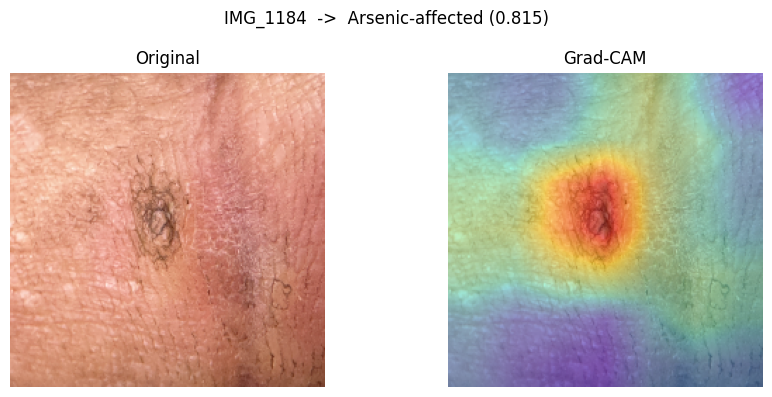


[Manually identified] lesion_pattern=keratotic_lesion, body_location=trunk

--- Ontology-generated clinical report ---
Prediction: Arsenic-affected (confidence 81.5%).
Clinical reasoning: Localized keratotic thickening on the trunk/forearm skin is consistent with early arsenical keratosis.
Risk note: Recommend monitoring for progression and checking palms/soles for co-occurring lesions.

IMG_1173  (Patchy/diffuse pigmentation pattern)


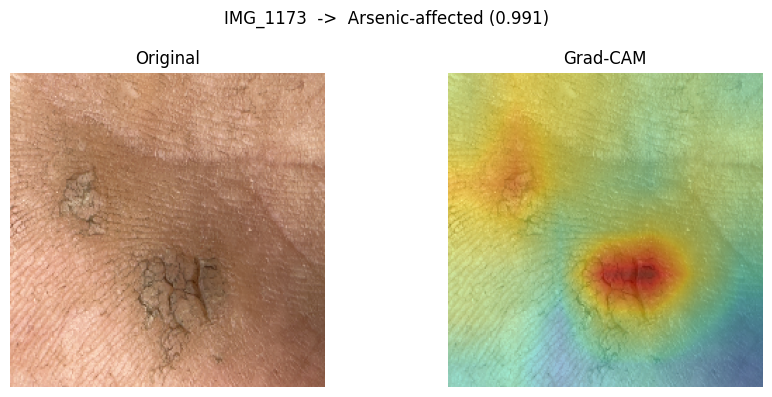


[Manually identified] lesion_pattern=diffuse_hyperpigmentation, body_location=trunk

--- Ontology-generated clinical report ---
Prediction: Arsenic-affected (confidence 99.1%).
Clinical reasoning: Diffuse spotted hyperpigmentation (melanosis) on the trunk is one of the earliest cutaneous signs of chronic arsenic exposure.
Risk note: Associated with long-term ingestion of contaminated groundwater; recommend confirmatory water-source testing and dermatology referral.

IMG_1176  (Multiple small keratotic spots)


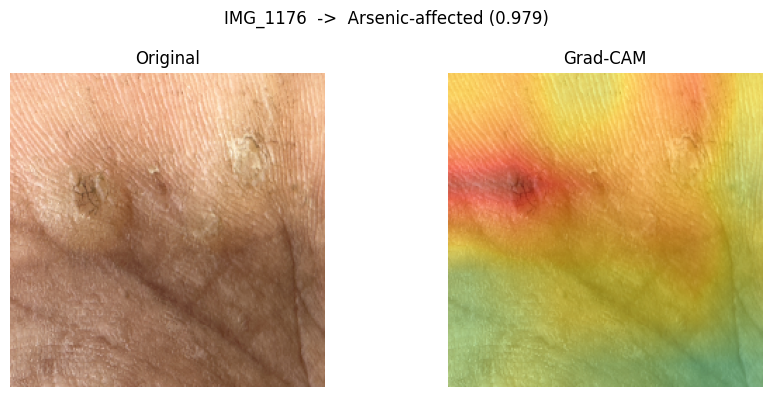


[Manually identified] lesion_pattern=keratotic_lesion, body_location=trunk

--- Ontology-generated clinical report ---
Prediction: Arsenic-affected (confidence 97.9%).
Clinical reasoning: Localized keratotic thickening on the trunk/forearm skin is consistent with early arsenical keratosis.
Risk note: Recommend monitoring for progression and checking palms/soles for co-occurring lesions.


All pipeline_demo_*.png files saved -- download these for the poster.


In [ ]:
"""
DAY 6-7: End-to-end pipeline demo -- ties together everything you've built:
CNN prediction -> Grad-CAM heatmap -> (manually identified) lesion type +
body location -> ontology-generated clinical report.

This is what you show your faculty: for each image, the full chain from
raw prediction to a clinically-framed explanation, not just a probability.

Run AFTER 00_session_setup.py has been executed in this session.
"""

import matplotlib.pyplot as plt

# ---------------- Ontology rule engine (from 03_ontology_rules.py) ----------------
from dataclasses import dataclass


@dataclass
class OntologyRule:
    lesion_pattern: str
    body_location: str
    explanation: str
    risk_note: str


RULES = [
    OntologyRule(
        lesion_pattern="diffuse_hyperpigmentation",
        body_location="trunk",
        explanation=(
            "Diffuse spotted hyperpigmentation (melanosis) on the trunk is "
            "one of the earliest cutaneous signs of chronic arsenic exposure."
        ),
        risk_note=(
            "Associated with long-term ingestion of contaminated groundwater; "
            "recommend confirmatory water-source testing and dermatology referral."
        ),
    ),
    OntologyRule(
        lesion_pattern="keratotic_lesion",
        body_location="palm",
        explanation=(
            "Punctate or diffuse keratosis on the palm is a classical marker of "
            "arsenical keratosis, often appearing after years of exposure."
        ),
        risk_note=(
            "Palmar/plantar keratosis carries elevated risk of progression to "
            "Bowen's disease if untreated; recommend closer monitoring."
        ),
    ),
    OntologyRule(
        lesion_pattern="keratotic_lesion",
        body_location="trunk",
        explanation=(
            "Localized keratotic thickening on the trunk/forearm skin is "
            "consistent with early arsenical keratosis."
        ),
        risk_note="Recommend monitoring for progression and checking palms/soles for co-occurring lesions.",
    ),
    OntologyRule(
        lesion_pattern="keratotic_lesion",
        body_location="sole",
        explanation=(
            "Keratotic thickening on the sole is consistent with arsenical "
            "keratosis, commonly co-occurring with palmar lesions."
        ),
        risk_note="Same progression risk as palmar keratosis; monitor both sites together.",
    ),
]


def match_rule(lesion_pattern, body_location):
    for rule in RULES:
        if rule.lesion_pattern == lesion_pattern and rule.body_location == body_location:
            return rule
    return None


def generate_report(cnn_label, cnn_confidence, lesion_pattern, body_location):
    if cnn_label != "Arsenic-affected":
        return (
            f"Prediction: {cnn_label} (confidence {cnn_confidence:.1%}). "
            "No arsenic-related lesion pattern detected in this image."
        )

    rule = match_rule(lesion_pattern, body_location)
    if rule is None:
        return (
            f"Prediction: Arsenic-affected (confidence {cnn_confidence:.1%}). "
            f"Lesion pattern '{lesion_pattern}' at '{body_location}' is not yet "
            "covered by the rule base -- flag for manual dermatologist review."
        )

    return (
        f"Prediction: Arsenic-affected (confidence {cnn_confidence:.1%}).\n"
        f"Clinical reasoning: {rule.explanation}\n"
        f"Risk note: {rule.risk_note}"
    )


# ==================================================================
# ---------------- Curated demo cases (edit as needed) --------------
# ==================================================================
# lesion_pattern and body_location are YOUR visual assessment of each
# image (the "manual bridge" -- see chat discussion). Based on the
# grid screenshots reviewed earlier:

DEMO_CASES = [
    {
        "img_path": "/content/data/Original/infacted/IMG_1184.JPG",
        "img_id": "IMG_1184",
        "lesion_pattern": "keratotic_lesion",
        "body_location": "trunk",
        "note": "Highest faithfulness score (0.502) -- best showcase example",
    },
    {
        "img_path": "/content/data/Original/infacted/IMG_1173.JPG",
        "img_id": "IMG_1173",
        "lesion_pattern": "diffuse_hyperpigmentation",
        "body_location": "trunk",
        "note": "Patchy/diffuse pigmentation pattern",
    },
    {
        "img_path": "/content/data/Original/infacted/IMG_1176.JPG",
        "img_id": "IMG_1176",
        "lesion_pattern": "keratotic_lesion",
        "body_location": "trunk",
        "note": "Multiple small keratotic spots",
    },
]

# ---------------- Run the full pipeline for each case ----------------
for case in DEMO_CASES:
    print(f"\n{'='*65}\n{case['img_id']}  ({case['note']})\n{'='*65}")

    display_arr, model_input = load_img_array(case["img_path"])
    heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
    gradcam_overlay = overlay_gradcam(display_arr, heatmap)

    label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

    # ---- show original + Grad-CAM side by side ----
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    fig.suptitle(f"{case['img_id']}  ->  {label} ({pred_prob:.3f})")
    axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
    axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
    plt.tight_layout()
    plt.savefig(f"pipeline_demo_{case['img_id']}.png", dpi=150)
    plt.show()

    # ---- ontology-generated clinical report ----
    report = generate_report(
        cnn_label=label,
        cnn_confidence=pred_prob,
        lesion_pattern=case["lesion_pattern"],
        body_location=case["body_location"],
    )
    print(f"\n[Manually identified] lesion_pattern={case['lesion_pattern']}, "
          f"body_location={case['body_location']}")
    print(f"\n--- Ontology-generated clinical report ---\n{report}")

print("\n\nAll pipeline_demo_*.png files saved -- download these for the poster.")

In [ ]:
!pip install streamlit pyngrok --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 39.2 MB/s eta 0:00:00


In [ ]:
from google.colab import files
uploaded = files.upload()  # এখানে 05_demo_app.py সিলেক্ট করো

Saving 05_demo_app.py to 05_demo_app.py


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3IRu1Amzgt2gBYByPpVSIQfjt2o_4qqTJqMRTzUyiEaWuXNLc")

!streamlit run 05_demo_app.py &>/content/logs.txt &

import time
time.sleep(5)  # স্ট্রিমলিট চালু হতে একটু সময় দাও

public_url = ngrok.connect(8501)
print("Demo app link:", public_url)

Demo app link: NgrokTunnel: "https://popper-undress-disregard.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
from google.colab import files
files.download("/content/data/Original/infacted/IMG_1184.JPG")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ধাপ ১: Drive mount + dataset + model (যদি আগের session হারিয়ে গিয়ে থাকে)
from google.colab import drive
drive.mount('/content/drive')
!cp /content/drive/MyDrive/arsenicosis_data/checkpoints/arsenicnet_baseline.keras /content/

# ধাপ ২: প্যাকেজ (যদি নতুন session হয়)
!pip install streamlit pyngrok --quiet

# ধাপ ৩: app চালু + নতুন tunnel
from pyngrok import ngrok
ngrok.set_auth_token("3IRu1Amzgt2gBYByPpVSIQfjt2o_4qqTJqMRTzUyiEaWuXNLc")  # এটা প্রতিবার লাগবে না যদি save হয়ে থাকে

!streamlit run 05_demo_app.py &>/content/logs.txt &

import time
time.sleep(5)

public_url = ngrok.connect(8501)
print("Demo app link:", public_url)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Demo app link: NgrokTunnel: "https://popper-undress-disregard.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
%%writefile /content/05_demo_app.py

Writing /content/05_demo_app.py


In [ ]:
!ls /content/05_demo_app.py  # নিশ্চিত করো ফাইল আছে

!pkill -f streamlit
!streamlit run /content/05_demo_app.py &>/content/logs.txt &

import time
time.sleep(8)

!cat /content/logs.txt

from pyngrok import ngrok
public_url = ngrok.connect(8501)
print("Demo app link:", public_url)

/content/05_demo_app.py


2026-08-27 06:55:52.881 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.111.243:8501

Demo app link: NgrokTunnel: "https://popper-undress-disregard.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!pkill -f streamlit

!streamlit run /content/05_demo_app.py \
    --server.enableCORS=false \
    --server.enableXsrfProtection=false \
    --server.headless=true \
    &>/content/logs.txt &

import time
time.sleep(8)
!cat /content/logs.txt

from pyngrok import ngrok
ngrok.kill()  # আগের পুরনো tunnel বন্ধ করে দাও
public_url = ngrok.connect(8501)
print("Demo app link:", public_url)



2026-08-27 07:02:03.131 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.111.243:8501

Demo app link: NgrokTunnel: "https://popper-undress-disregard.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
!curl -s http://localhost:8501 | head -30

<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
 See the License for the specific language governing permissions and
 limitations under the License.
-->

<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta
      name="viewport"
      content="width=device-width, initial-scale=1, shrink-to-fit=no"
    />
    <link rel="shortcut icon" href="./favicon.png" />
    <link
      rel="preload"
      href="./static/media/SourceSansVF-Upright.ttf.BsWL4Kly.woff2"
      as="font"
      type="font/woff2"


In [ ]:
from google.colab.output import eval_js
proxy_url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Demo app link:", proxy_url)

Demo app link: https://8501-gpu-t4-s-kkb-ass1c0-imlbt2opz2a4-c.asia-southeast1-0.prod.colab.dev


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [ ]:
!pkill -f streamlit

!streamlit run /content/05_demo_app.py \
    --server.enableCORS=false \
    --server.enableXsrfProtection=false \
    --server.headless=true \
    &>/content/logs.txt &

import time
time.sleep(8)
!cat /content/logs.txt



2026-08-27 07:14:00.538 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.111.243:8501



In [ ]:
get_ipython().system_raw('./cloudflared tunnel --url http://localhost:8501 &>/content/cloudflared_logs.txt &')

import time
time.sleep(8)

!grep -o 'https://.*trycloudflare.com' /content/cloudflared_logs.txt

https://organized-allan-modems-license.trycloudflare.com


In [ ]:
!cat /content/cloudflared_logs.txt

2026-08-27T07:14:25Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-27T07:14:25Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-27T07:14:31Z INF +--------------------------------------------------------------------------------------------+
2026-08-27T07:14:31Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-27T07:14:31Z INF |  https://organized-allan-modems-license.trycloudflare.

In [ ]:
!cat /content/logs.txt



2026-08-27 07:14:00.538 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.111.243:8501



In [ ]:
!pkill -f streamlit
!pkill -f cloudflared

import time
time.sleep(3)

!streamlit run /content/05_demo_app.py \
    --server.enableCORS=false \
    --server.enableXsrfProtection=false \
    --server.headless=true \
    &>/content/logs.txt &

time.sleep(10)
print("--- Streamlit logs ---")
!cat /content/logs.txt

get_ipython().system_raw('./cloudflared tunnel --url http://localhost:8501 &>/content/cloudflared_logs.txt &')
time.sleep(10)

print("\n--- New link ---")
!grep -o 'https://.*trycloudflare.com' /content/cloudflared_logs.txt

--- Streamlit logs ---


2026-08-27 07:20:36.730 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.111.243:8501


--- New link ---
https://compliant-societies-define-fundamentals.trycloudflare.com


**Next time for showing and Session out, from here we will start to run**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/Original.zip" -d "/content/data"
!cp /content/drive/MyDrive/arsenicosis_data/checkpoints/arsenicnet_baseline.keras /content/
!pip install lime scikit-image --quiet

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.applications.efficientnet import preprocess_input
from dataclasses import dataclass

MODEL_PATH = "arsenicnet_baseline.keras"
IMG_SIZE = (224, 224)
LAST_CONV_LAYER = "top_conv"

model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded successfully.")

def load_img_array(img_path):
    img = keras_image.load_img(img_path, target_size=IMG_SIZE)
    raw = keras_image.img_to_array(img)
    model_input = preprocess_input(raw.copy())
    display_arr = raw / 255.0
    return display_arr, model_input

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(np.expand_dims(img_array, axis=0))
        class_channel = predictions[:, 0]
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(predictions[0][0])

def overlay_gradcam(display_arr, heatmap, alpha=0.4):
    heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
    jet = plt.get_cmap("jet")
    jet_heatmap = jet(heatmap_resized)[:, :, :3]
    return np.clip(jet_heatmap * alpha + display_arr * (1 - alpha), 0, 1)

@dataclass
class OntologyRule:
    lesion_pattern: str
    body_location: str
    explanation: str
    risk_note: str

RULES = [
    OntologyRule("diffuse_hyperpigmentation", "trunk",
        "Diffuse spotted hyperpigmentation (melanosis) on the trunk is one of the earliest cutaneous signs of chronic arsenic exposure.",
        "Associated with long-term ingestion of contaminated groundwater; recommend confirmatory water-source testing and dermatology referral."),
    OntologyRule("keratotic_lesion", "palm",
        "Punctate or diffuse keratosis on the palm is a classical marker of arsenical keratosis.",
        "Elevated risk of progression to Bowen's disease if untreated; recommend closer monitoring."),
    OntologyRule("keratotic_lesion", "sole",
        "Keratotic thickening on the sole is consistent with arsenical keratosis.",
        "Same progression risk as palmar keratosis; monitor both sites together."),
    OntologyRule("keratotic_lesion", "trunk",
        "Localized keratotic thickening on trunk/forearm skin is consistent with early arsenical keratosis.",
        "Recommend monitoring for progression and checking palms/soles for co-occurring lesions."),
]

def generate_report(cnn_label, cnn_confidence, lesion_pattern, body_location):
    if cnn_label != "Arsenic-affected":
        return f"Prediction: {cnn_label} (confidence {cnn_confidence:.1%}). No arsenic-related lesion pattern detected."
    for rule in RULES:
        if rule.lesion_pattern == lesion_pattern and rule.body_location == body_location:
            return (f"Prediction: Arsenic-affected (confidence {cnn_confidence:.1%})\n"
                    f"Clinical reasoning: {rule.explanation}\n"
                    f"Risk note: {rule.risk_note}")
    return f"Prediction: Arsenic-affected (confidence {cnn_confidence:.1%}). Pattern not in rule base -- flag for manual review."

print("Setup complete. Ready for demo.")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 23.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Model loaded successfully.
Setup complete. Ready for demo.


In [ ]:
import os
files_list = sorted(os.listdir("/content/data/Original/not_infacted"))
print(f"Total: {len(files_list)} files")
print(files_list[:30])  # প্রথম ২০টা দেখাও

Total: 546 files
['IMG-20230529-WA0000.jpg', 'IMG-20230529-WA0001.jpg', 'IMG-20230529-WA0002.jpg', 'IMG-20230529-WA0003.jpg', 'IMG-20230529-WA0004.jpg', 'IMG-20230529-WA0005.jpg', 'IMG-20230529-WA0006.jpg', 'IMG-20230529-WA0007.jpg', 'IMG-20230529-WA0008.jpg', 'IMG-20230529-WA0009.jpg', 'IMG-20230529-WA0010.jpg', 'IMG-20230529-WA0011.jpg', 'IMG-20230529-WA0012.jpg', 'IMG-20230529-WA0013.jpg', 'IMG-20230529-WA0014.jpg', 'IMG-20230529-WA0015.jpg', 'IMG-20230529-WA0016.jpg', 'IMG-20230529-WA0017.jpg', 'IMG-20230529-WA0018.jpg', 'IMG-20230529-WA0019.jpg', 'IMG-20230529-WA0020.jpg', 'IMG-20230529-WA0021.jpg', 'IMG-20230529-WA0022.jpg', 'IMG-20230529-WA0023.jpg', 'IMG-20230529-WA0024.jpg', 'IMG-20230529-WA0025.jpg', 'IMG-20230529-WA0026.jpg', 'IMG-20230529-WA0027.jpg', 'IMG-20230529-WA0028.jpg', 'IMG-20230529-WA0029.jpg']


Selected: /content/data/Original/infacted/IMG_1741.JPG


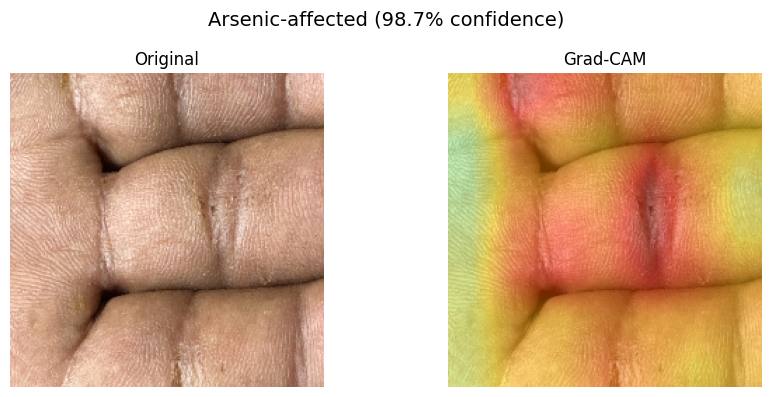

Prediction: Arsenic-affected (confidence 98.7%)
Clinical reasoning: Localized keratotic thickening on trunk/forearm skin is consistent with early arsenical keratosis.
Risk note: Recommend monitoring for progression and checking palms/soles for co-occurring lesions.


In [ ]:
import os, random

infacted_dir = "/content/data/Original/infacted"
random_file = random.choice(os.listdir(infacted_dir))
img_path = os.path.join(infacted_dir, random_file)
print(f"Selected: {img_path}")

lesion_pattern = "keratotic_lesion"
body_location = "trunk"

display_arr, model_input = load_img_array(img_path)
heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
gradcam_overlay = overlay_gradcam(display_arr, heatmap)
label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle(f"{label} ({pred_prob:.1%} confidence)", fontsize=14)
axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
plt.tight_layout()
plt.show()

print(generate_report(label, pred_prob, lesion_pattern, body_location))

In [ ]:
lesion_pattern = "diffuse_hyperpigmentation"
body_location = "trunk"

Selected: /content/data/Original/not_infacted/IMG_20230612_130400.jpg


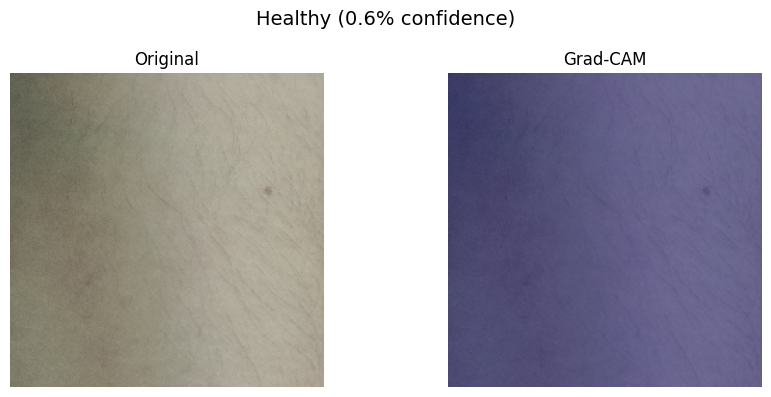

Prediction: Healthy (confidence 0.6%). No arsenic-related lesion pattern detected.


In [ ]:
import os, random

not_infacted_dir = "/content/data/Original/not_infacted"
random_file = random.choice(os.listdir(not_infacted_dir))
img_path = os.path.join(not_infacted_dir, random_file)
print(f"Selected: {img_path}")

lesion_pattern = "keratotic_lesion"
body_location = "trunk"

display_arr, model_input = load_img_array(img_path)
heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
gradcam_overlay = overlay_gradcam(display_arr, heatmap)
label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle(f"{label} ({pred_prob:.1%} confidence)", fontsize=14)
axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
plt.tight_layout()
plt.show()

print(generate_report(label, pred_prob, lesion_pattern, body_location))

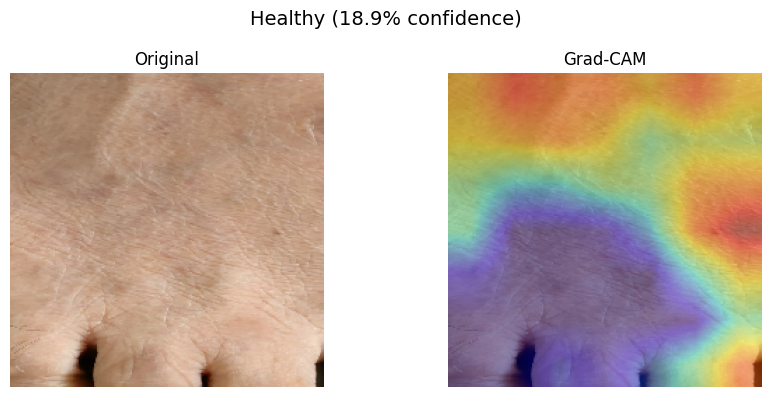

Prediction: Healthy (confidence 18.9%). No arsenic-related lesion pattern detected.


In [ ]:
# ============ LIVE DEMO -- image path বদলে বারবার চালাও ============
img_path = "/content/data/Original/not_infacted/IMG-20230529-WA0000.jpg"   # <- এখানে path বদলাও
lesion_pattern = "diffuse_hyperpigmentation"   # চোখে দেখে সিলেক্ট করো
body_location = "trunk"               # চোখে দেখে সিলেক্ট করো

display_arr, model_input = load_img_array(img_path)
heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
gradcam_overlay = overlay_gradcam(display_arr, heatmap)
label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle(f"{label} ({pred_prob:.1%} confidence)", fontsize=14)
axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
plt.tight_layout()
plt.show()

print(generate_report(label, pred_prob, lesion_pattern, body_location))

In [ ]:
DEMO_IMAGES = [
    {
        "path": "/content/data/Original/infacted/IMG_1516.JPG",
        "note": "সবচেয়ে স্পষ্ট affected কেস — 99.7% confidence, চোখে দেখা lesion-এর সাথে Grad-CAM পুরোপুরি মিলে যায়। প্রথমে এটা দেখাও।",
    },
    {
        "path": "/content/data/Original/infacted/IMG_1184.JPG",
        "note": "Highest faithfulness score (IoU=0.502) — Grad-CAM+ontology একসাথে দেখানোর জন্য সেরা উদাহরণ।",
    },
    {
        "path": "/content/data/Original/infacted/IMG_1173.JPG",
        "note": "99.1% confidence, diffuse/multi-spot pattern — ontology-তে melanosis rule দেখানোর জন্য ভালো।",
    },
    {
        "path": "/content/data/Original/not_infacted/IMG_20230616_153421.jpg",
        "note": "স্পষ্ট healthy কেস — 99.7% নিশ্চিত healthy, কোনো heatmap activation নেই। Healthy বনাম affected তুলনা দেখানোর জন্য।",
    },
    {
        "path": "/content/data/Original/not_infacted/IMG_2068.JPG",
        "note": "সঠিক কিন্তু কম confidence-এর healthy কেস (74.5% নিশ্চিত) — 'borderline/uncertain case' discussion-এর জন্য ভালো, misclassification না।",
    },
]

for demo in DEMO_IMAGES:
    print(demo["path"], "--", demo["note"])

/content/data/Original/infacted/IMG_1516.JPG -- সবচেয়ে স্পষ্ট affected কেস — 99.7% confidence, চোখে দেখা lesion-এর সাথে Grad-CAM পুরোপুরি মিলে যায়। প্রথমে এটা দেখাও।
/content/data/Original/infacted/IMG_1184.JPG -- Highest faithfulness score (IoU=0.502) — Grad-CAM+ontology একসাথে দেখানোর জন্য সেরা উদাহরণ।
/content/data/Original/infacted/IMG_1173.JPG -- 99.1% confidence, diffuse/multi-spot pattern — ontology-তে melanosis rule দেখানোর জন্য ভালো।
/content/data/Original/not_infacted/IMG_20230616_153421.jpg -- স্পষ্ট healthy কেস — 99.7% নিশ্চিত healthy, কোনো heatmap activation নেই। Healthy বনাম affected তুলনা দেখানোর জন্য।
/content/data/Original/not_infacted/IMG_2068.JPG -- সঠিক কিন্তু কম confidence-এর healthy কেস (74.5% নিশ্চিত) — 'borderline/uncertain case' discussion-এর জন্য ভালো, misclassification না।


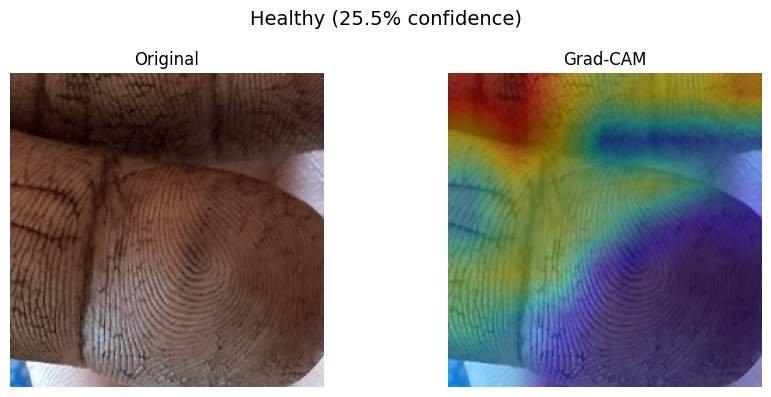

Prediction: Healthy (confidence 25.5%). No arsenic-related lesion pattern detected.


In [ ]:
img_path = DEMO_IMAGES[4]["path"]   # ইনডেক্স বদলে বদলে দেখাও (0,1,2,3,4)

display_arr, model_input = load_img_array(img_path)
heatmap, pred_prob = make_gradcam_heatmap(model_input, model, LAST_CONV_LAYER)
gradcam_overlay = overlay_gradcam(display_arr, heatmap)
label = "Arsenic-affected" if pred_prob > 0.5 else "Healthy"

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle(f"{label} ({pred_prob:.1%} confidence)", fontsize=14)
axes[0].imshow(display_arr); axes[0].set_title("Original"); axes[0].axis("off")
axes[1].imshow(gradcam_overlay); axes[1].set_title("Grad-CAM"); axes[1].axis("off")
plt.tight_layout()
plt.show()

lesion_pattern = "keratotic_lesion"  # ছবি অনুযায়ী বদলাও (IMG_1173-এর জন্য "diffuse_hyperpigmentation")
body_location = "trunk"
print(generate_report(label, pred_prob, lesion_pattern, body_location))